# Transaction 분석: 세 기간 통합 로그와 비지도 이상탐지


연구 주제: **대규모 로그 데이터 기반 비지도 학습 이상탐지 AI 모델 개발**

다음 세 기간의 실제 로그를 합쳐 분석합니다. 각 행에 `source_period`, `source_file`을
남겨 통합 분포와 기간별 차이를 함께 확인합니다.

| 기간 폴더 | 수집 범위 |
|---|---|
| `25년12월24일-26년4월6일` | 2025-12-24 ~ 2026-04-06 |
| `26년8월15일-26년9월14일` | 2026-08-15 ~ 2026-09-14 |
| `26년9월30일-26년10월2일` | 2026-09-30 ~ 2026-10-02 |

파일명과 확장자가 실제 내용과 다른 최근 기간은 **컬럼 구조**로 소스를 선택합니다.
트랜잭션은 `EC_MESSAGE_BODY.csv` 안의 SQL 트랜잭션 테이블,
프로세스는 `EC_TRANSACTION_MONITORING.csv` 안의 프로세스 CSV를 사용합니다.
메시지 로그인 `EC_PROCESS_MONITORING.csv`는 프로세스 분석에 섞지 않습니다.

시간대가 있는 시각은 한국 시간으로 변환하고, 시간대 없는 원본 시각은 한국 시간으로
해석합니다. 기간 사이의 공백과 관측되지 않은 시간 구간은 수집 여부를 알 수 없으므로
트래픽 0으로 채우지 않습니다. 통계적 이상치, 실패 상태, 정합성 위반은 검토 후보이며
실제 이상 여부를 확정하는 정답 라벨이 아닙니다.

실행 환경: Python 3.10+, pandas 2+, numpy, matplotlib, seaborn, scikit-learn 1.2+.
세 노트북과 `log_analysis_common.py`, `log_analysis_visuals.py`를 같은 `code/` 폴더에 둡니다.
전체 통계는 원본 전체를 사용하고, 그래프·PCA·모델 학습 표본만 크기를 제한합니다.
분석 표와 그래프는 노트북에서 확인하며 별도 결과 파일은 생성하지 않습니다.

### 그래프 읽는 순서

① 파란색 = 2025.12–2026.04, ② 초록색 = 2026.08–09,
③ 주황색 = 2026.09.30–10.02입니다. 빨간색은 점검 후보·비교 기준선입니다.
각 그림 아래 **실제 결과 → 의미 → 모델 개발에 반영**을 함께 읽습니다.
**전체 데이터**는 발생률·통계 계산, **균형 표본**은 분포·산점도 비교에 사용합니다.
기간별 표본 추출률은 첫 그래프에 명시합니다. 그림에서 일부 범위를 확대할 경우
화면 밖 행 수를 표시하며 모델 계산에서는 제외하지 않습니다.
실행한 그래프와 해석은 노트북 출력에 포함해 파일을 열면 바로 확인할 수 있습니다.

> 공개 저장소용 연구 스냅샷입니다. 원본·평가 데이터셋과 학습/검증 캐시, 행별 예측 배열은 포함하지 않습니다. 개별 원본 로그 미리보기 출력은 제거했습니다. 집계 표와 그림은 저장된 실험 결과이며, 원본 기반 분석을 재실행하려면 별도 데이터가 필요합니다.

## 1. 환경 설정과 세 기간 통합 로드

공통 로더는 대문자/소문자 컬럼명, CSV/SQL 형식, 결측치 표기를 통일합니다.
`responseCode`는 문자열로 유지하므로 성공 코드 `0000`의 앞자리 0이 사라지지 않습니다.
중복 내보내기 파일은 하나만 선택하고 분석 컬럼이 모두 같은 행만 제거합니다.
재시도 및 같은 키의 서로 다른 로그는 유지하고 감사 표에 집계합니다.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "code" / "log_analysis_common.py").exists() and (p / "data").is_dir())
if str(ROOT / "code") not in sys.path:
    sys.path.insert(0, str(ROOT / "code"))
from log_analysis_common import (
    PERIODS, load_logs, text, quality_table, numeric_summary, add_time_features,
    sample_by_period, time_summary, hourly_history_candidates, iqr_summary,
    contextual_duration, numeric_drift, categorical_drift, dependency_features,
    latest_transaction_state, transaction_process_summary, fit_anomaly_baseline,
    baseline_report, signed_log, setup_plotting,
)
from log_analysis_visuals import (
    plot_sampling, plot_missingness, plot_numeric_distributions, plot_categories,
    plot_period_timeseries, plot_hour_pattern, plot_traffic_candidates,
    plot_statistical_candidates, plot_drift, plot_correlation, plot_model_scores,
    plot_projection, plot_rule_rates, plot_dependency, plot_merge_counts,
    plot_merge_status, plot_merge_performance, plot_sequences, note,
)

DATA_DIR = ROOT / "data"
RANDOM_STATE = 42
PLOT_SAMPLE = 30_000
MAX_TRAIN_ROWS = 100_000
SCORE_BATCH_ROWS = 100_000
ALERT_QUANTILE = 0.99
setup_plotting()


In [ ]:
df, source_audit = load_logs("transaction", DATA_DIR)
display(source_audit)
print(f"원본 합계: {source_audit['raw_rows'].sum():,}건")
print(f"분석 합계: {len(df):,}건 / {df.shape[1]}개 컬럼")
print(f"메모리 사용량: {df.memory_usage(deep=True).sum() / 1024**2:,.1f} MiB")
display(df.head())


## 2. 스키마·결측·중복·관측 범위

파싱 실패, 중복 키, 결측 시간과 기간별 결측률을 먼저 확인합니다.
`observed_days`는 실제 로그가 존재하는 날짜 수로, 폴더명의 일수와 다를 수 있습니다.
짧은 구간의 부족한 로그나 누락 컬럼을 장애로 바로 해석하지 않습니다.

In [ ]:
display(quality_table(df))
missing_by_period = df.isna().groupby(df["source_period"], observed=True).mean().mul(100)
display(missing_by_period.round(2))
period_volume = source_audit.set_index("source_period")[["raw_rows", "rows", "observed_days"]].copy()
period_volume["share_pct"] = period_volume["rows"] / len(df) * 100
period_volume["rows_per_observed_day"] = period_volume["rows"] / period_volume["observed_days"]
display(period_volume.round(2))


### 2.1 전체 규모와 균형 표본은 다릅니다

왼쪽은 전체 행 수, 오른쪽은 원본과 시각화 표본의 기간 구성입니다.
표본은 기간별 최대 1만 행을 고정 시드로 추출합니다.
실제 장애 발생률이나 결측률은 이 표본이 아닌 전체 데이터에서 계산합니다.

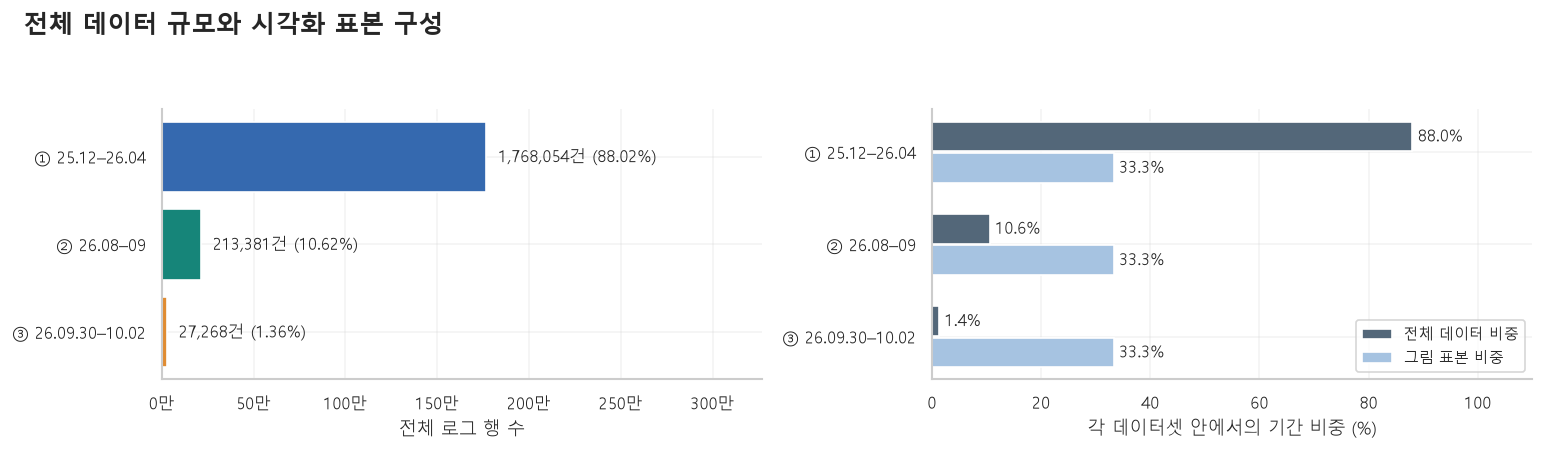

,전체 행 수,그림 표본 행 수,전체 내 비중 (%),표본 내 비중 (%),기간별 추출률 (%)
source_period,,,,,
① 25.12–26.04,1768054,10000,88.020,33.333,0.566
② 26.08–09,213381,10000,10.623,33.333,4.686
③ 26.09.30–10.02,27268,10000,1.357,33.333,36.673


**실제 결과**

- 전체 2,008,703건 중 ① 25.12–26.04가 88.02%입니다. 시각화는 30,000건을 기간별 균형 추출했습니다.

**의미**: 통합 건수 그래프는 가장 큰 기간의 특성을 주로 보여줍니다. 균형 표본은 짧은 기간을 비교하기 위한 것으로 전체 발생 비율을 대표하지 않습니다.

**모델 개발에 반영**: 전체 통계로 발생률을 계산하고, 기간별 표본으로 분포 형태를 비교합니다. 표본 추출률이 큰 최근 기간을 전체 비중으로 오해하지 않습니다.

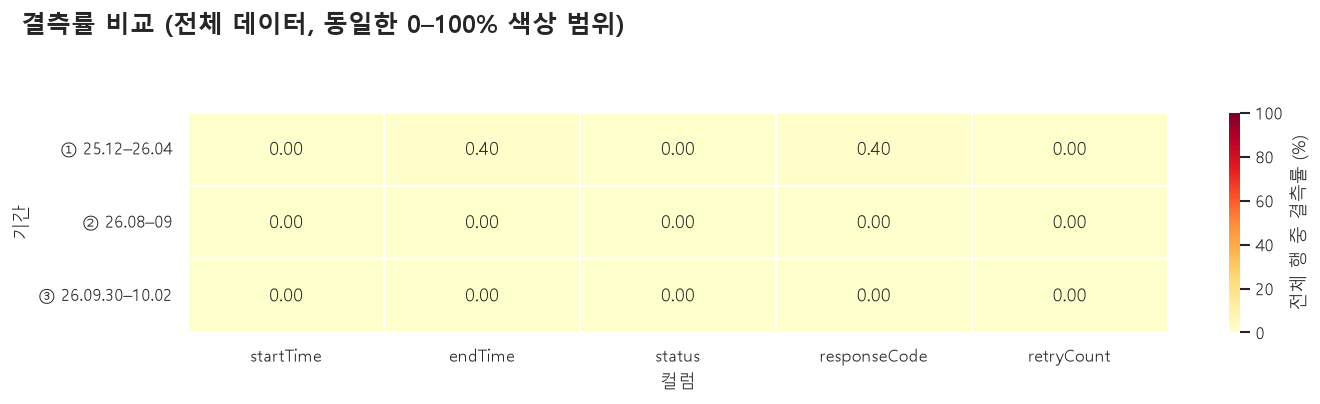

**실제 결과**

- ① 25.12–26.04: 종료시각 결측 7,060건 (0.40%).
- ② 26.08–09: 종료시각 결측 0건 (0.00%).
- ③ 26.09.30–10.02: 종료시각 결측 0건 (0.00%).

**의미**: 종료시각 결측은 처리시간을 계산할 수 없는 로그입니다. 미완료 상태·수집 누락을 구분해야 하며 처리시간 0으로 대치하면 분포가 왜곡됩니다.

**모델 개발에 반영**: 결측 여부 피처를 유지하고, 완료 로그 지연 탐지와 미완료 로그 탐지를 분리합니다. 0.00%는 반올림된 값일 수 있으므로 건수도 확인합니다.

In [4]:
plot_df = sample_by_period(df, PLOT_SAMPLE, RANDOM_STATE)
sample_audit = plot_sampling(df, plot_df)
plot_missingness(df, ["startTime", "endTime", "status", "responseCode", "retryCount"])


주요 컬럼: `interfaceId`는 업무 종류, 채널/허브는 실행 경로, `processCount`는 선언된
프로세스 수, `retryCount`는 재시도, `processTime`은 기록된 밀리초 처리시간입니다.
`status`/`responseCode`는 실행 결과이며, 학습의 정답 라벨로 사용하지 않습니다.

## 3. 처리시간과 수치 분포

처리시간은 `endTime - startTime`의 밀리초 값입니다. 음수·0·결측과
p95/p99/p99.9를 확인해 긴 꼬리와 불완전한 실행 로그를 구분합니다.
음수는 검증을 위해 유지합니다. 시간 분포는 실제 단위의 로그 눈금으로 읽고,
이산 카운트 값은 전체 행의 100% 구성 막대로 비교합니다.
모든 기간은 같은 히스토그램 구간과 세로축을 사용합니다.

In [5]:
add_time_features(df)
NUMERIC_COLS = ['duration_ms', 'processTime', 'processCount', 'retryCount']
display(numeric_summary(df, NUMERIC_COLS))
print(f"음수 처리시간: {df['negative_duration'].sum():,}건")
print(f"종료시각 없음: {df['missing_end'].sum():,}건")


,count,mean,std,min,1%,25%,50%,75%,95%,99%,99.9%,max,missing_pct,zero_pct,negative_count,skewness
duration_ms,2001643.0,5358.338,96904.603,1.0,3.0,144.0,4814.0,7514.0,9617.0,10818.0,216979.07,33781607.0,0.351,0.0,0,284.234
processTime,2001643.0,5358.338,96904.603,1.0,3.0,144.0,4814.0,7514.0,9617.0,10818.0,216979.07,33781607.0,0.351,0.0,0,284.234
processCount,2008700.0,1.856,0.400,1.0,1.0,2.0,2.0,2.0,2.0,3.0,3.00,19.0,0.000,0.0,0,-1.081
retryCount,2008703.0,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.000,100.0,0,0.000


음수 처리시간: 0건
종료시각 없음: 7,060건


In [6]:
# duration_ms 등 파생 컬럼을 포함해 동일 시드로 표본을 다시 구성합니다.
plot_df = sample_by_period(df, PLOT_SAMPLE, RANDOM_STATE)


### 수치 분포: `duration_ms`

기간별 분포를 같은 축으로 비교하고 바로 아래 결과 해석을 읽습니다.

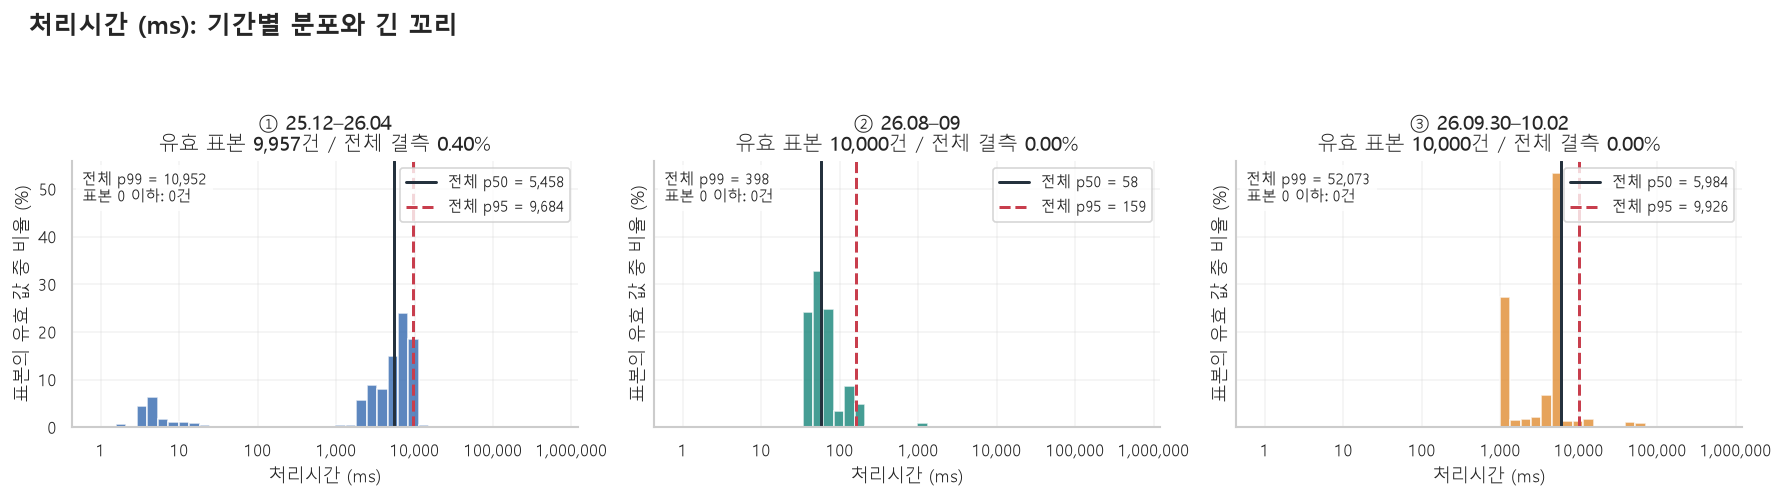

**실제 결과**

- ① 25.12–26.04: 전체 중앙값 5,458, p95 9,684, p99 10,952.
- ② 26.08–09: 전체 중앙값 58, p95 159, p99 398.
- ③ 26.09.30–10.02: 전체 중앙값 5,984, p95 9,926, p99 52,073.

**의미**: 가로축은 로그 간격이지만 눈금은 실제 단위입니다. 히스토그램은 같은 구간·같은 세로축을 사용하는 균형 표본이며 선과 분위수는 전체 데이터입니다. p95보다 큰 값은 전체 유효 값의 최대 약 5%입니다(동률 제외). 표본에 없는 극단값은 히스토그램 범위 밖일 수 있으며 전체 통계 표에서 확인합니다.

**모델 개발에 반영**: 절대 처리시간과 업무별 상대 지연을 함께 사용합니다. 중앙값 차이가 크면 기간·업무 그룹 기준선을 비교하고, 긴 꼬리에는 log1p 변환을 적용합니다. 음수·0·결측은 별도 정합성 점검 대상입니다.

In [7]:
plot_numeric_distributions(df, plot_df, ['duration_ms'])


### 수치 분포: `processCount`

기간별 분포를 같은 축으로 비교하고 바로 아래 결과 해석을 읽습니다.

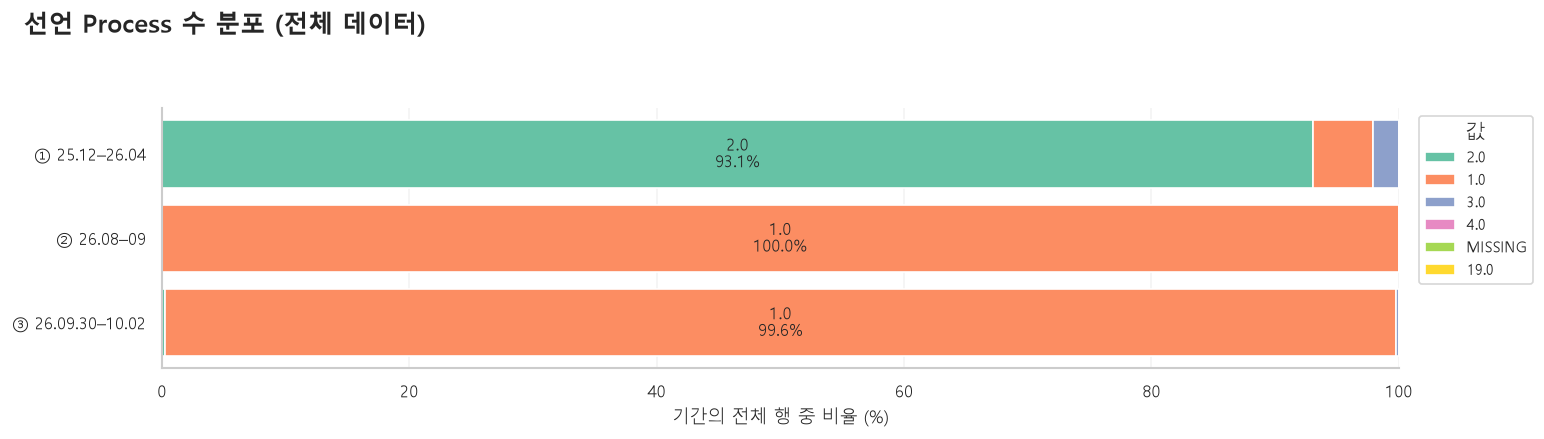

**실제 결과**

- ① 25.12–26.04: 최빈값 2.0, 1,645,858건 (93.09%).
- ② 26.08–09: 최빈값 1.0, 213,286건 (99.96%).
- ③ 26.09.30–10.02: 최빈값 1.0, 27,157건 (99.59%).

**의미**: 기간별 막대의 길이를 100%로 맞췄기 때문에 규모가 아니라 값의 구성 차이를 비교합니다. 처리 건수의 의미·단위는 어댑터마다 다를 수 있습니다.

**모델 개발에 반영**: 연속형 정규분포를 가정하지 않고 범주형/카운트 특성을 반영합니다. 기간·업무 구성이 다른데 공통 IQR을 적용하면 정상 값도 대량 경보가 될 수 있습니다.

In [8]:
plot_numeric_distributions(df, plot_df, ['processCount'])


### 수치 분포: `retryCount`

기간별 분포를 같은 축으로 비교하고 바로 아래 결과 해석을 읽습니다.

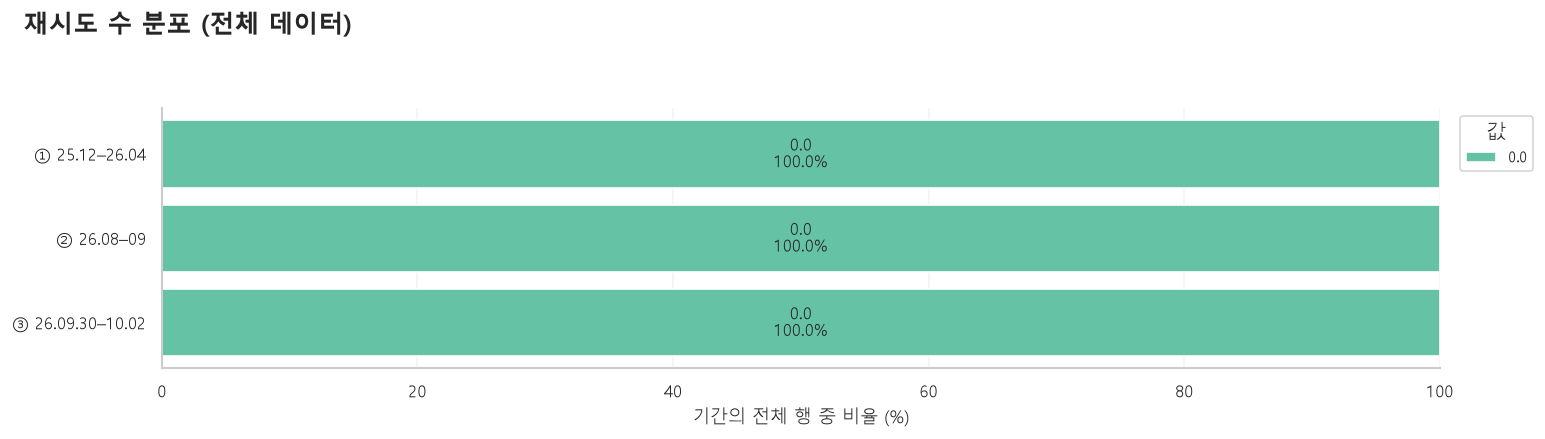

**실제 결과**

- ① 25.12–26.04: 최빈값 0.0, 1,768,054건 (100.00%).
- ② 26.08–09: 최빈값 0.0, 213,381건 (100.00%).
- ③ 26.09.30–10.02: 최빈값 0.0, 27,268건 (100.00%).

**의미**: 모든 유효 값이 같습니다. 이 표본에서는 이 변수만으로 로그를 구분할 수 없습니다.

**모델 개발에 반영**: 상수 피처는 현재 모델에서 변별력이 없습니다. 향후 새 값 출현은 별도로 감시합니다.

In [9]:
plot_numeric_distributions(df, plot_df, ['retryCount'])


### 3.1 가장 긴 실행은 별도 확인

긴 실행이 실제 지연인지, 배치 업무의 정상 실행인지 상태와 업무 종류를 확인합니다.
아래 표는 전체 데이터의 상위 실행이며, 표본 히스토그램에 없을 수도 있습니다.

In [ ]:
display(df.nlargest(10, "duration_ms")[["source_period", "transactionId", "startTime", "status", "duration_ms"]])
note(f"전체 유효 처리시간 최대 {df['duration_ms'].max():,.0f}ms; "
     f"음수 {df['negative_duration'].sum():,}건, 종료시각 결측 {df['missing_end'].sum():,}건.",
     "상위 실행만으로 정상/이상을 확정하지 않습니다. 완료 실행의 긴 꼬리와 종료 로그가 없는 실행은 다른 탐지 대상입니다.",
     "상위 실행을 업무별 분포와 비교하고, 미완료 로그는 별도의 경과시간 기반 감시를 설계합니다.")


## 4. 일별·시간별 트래픽과 처리시간 추이

기간별 그래프를 분리해 수집 공백을 가로질러 선을 잇지 않습니다.
집계는 전체 로그를 사용합니다. 실패율의 분모는 상태가 알려진 로그 수이며,
실패 상태 비율은 참고 지표입니다.

,observed_days,rows,median_daily_rows,max_daily_rows
source_period,,,,
25년12월24일-26년4월6일,59,1768054,14.0,329988
26년8월15일-26년9월14일,19,213381,10000.0,25922
26년9월30일-26년10월2일,3,27268,186.0,27051


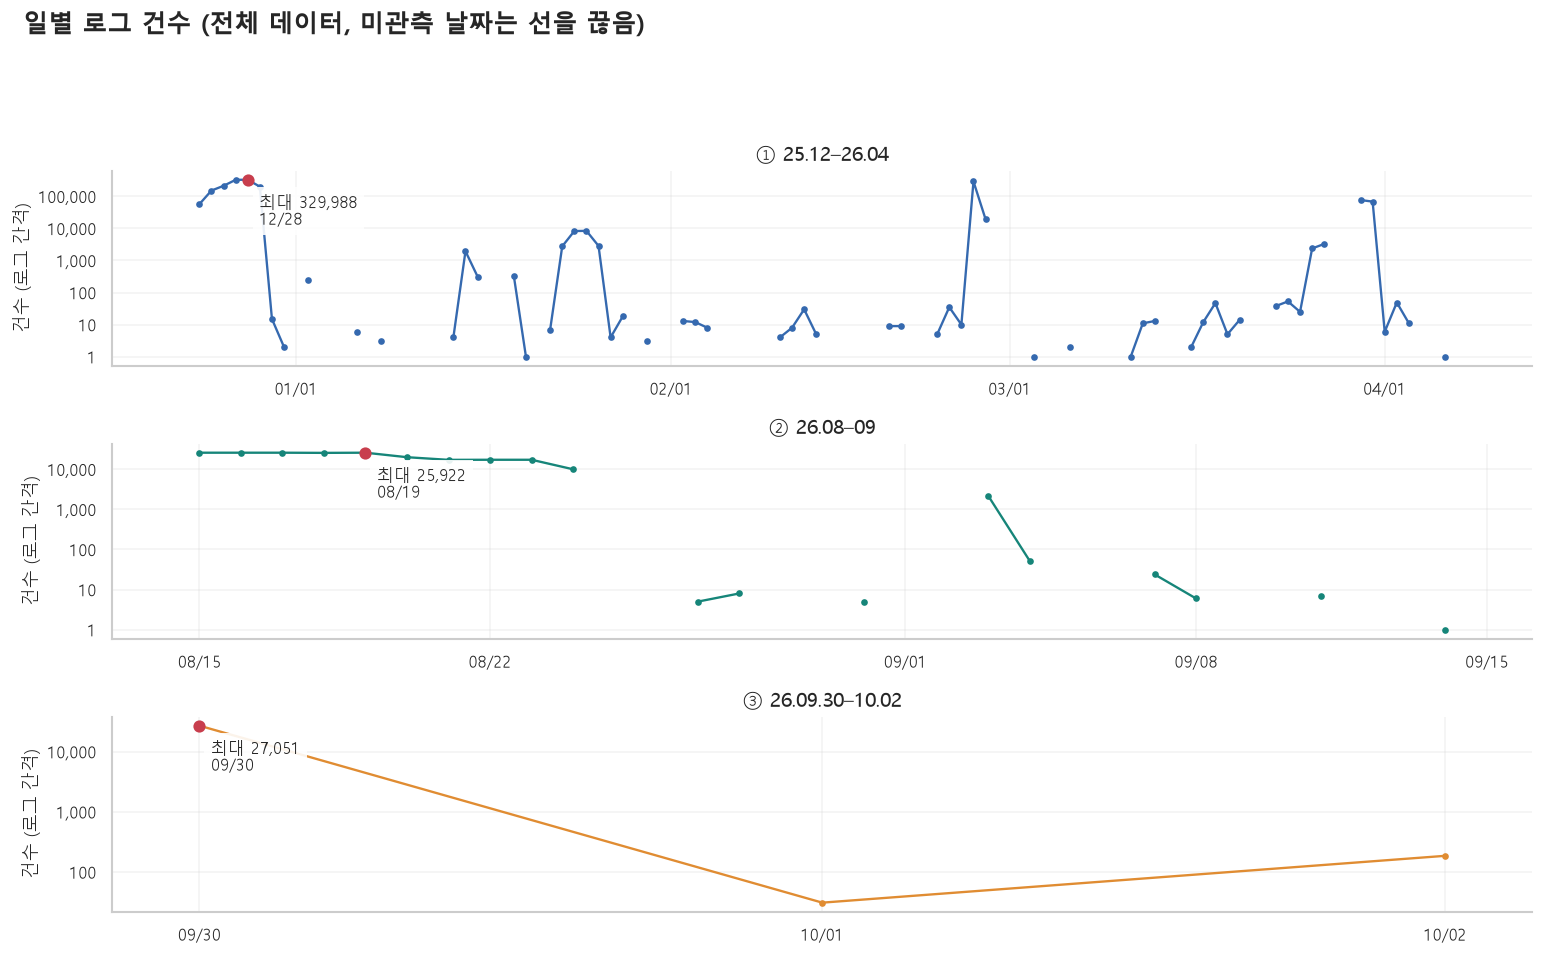

**실제 결과**

- ① 25.12–26.04: 관측 59일, 최대 329,988 (2025-12-28).
- ② 26.08–09: 관측 19일, 최대 25,922 (2026-08-19).
- ③ 26.09.30–10.02: 관측 3일, 최대 27,051 (2026-09-30).

**의미**: 건수·p95는 로그 눈금으로 작은 기간도 읽을 수 있게 했고, 실패율은 동일한 0–100% 범위로 표시했습니다. 수집되지 않은 날짜는 0이 아니라 미관측입니다. 날짜별 p95는 관측 건수가 적으면 불안정합니다.

**모델 개발에 반영**: 시간대·요일·업무량을 조건으로 한 기준선과 지연/실패 동시 변화를 검토합니다. 건수 증가만으로 장애를 판정하지 않습니다.

In [11]:
daily = time_summary(df, "D")
hourly = time_summary(df, "h")
display(daily.groupby("source_period", observed=True).agg(
    observed_days=("bin", "size"), rows=("rows", "sum"),
    median_daily_rows=("rows", "median"), max_daily_rows=("rows", "max")))
plot_period_timeseries(daily, "rows", "일별 로그 건수")


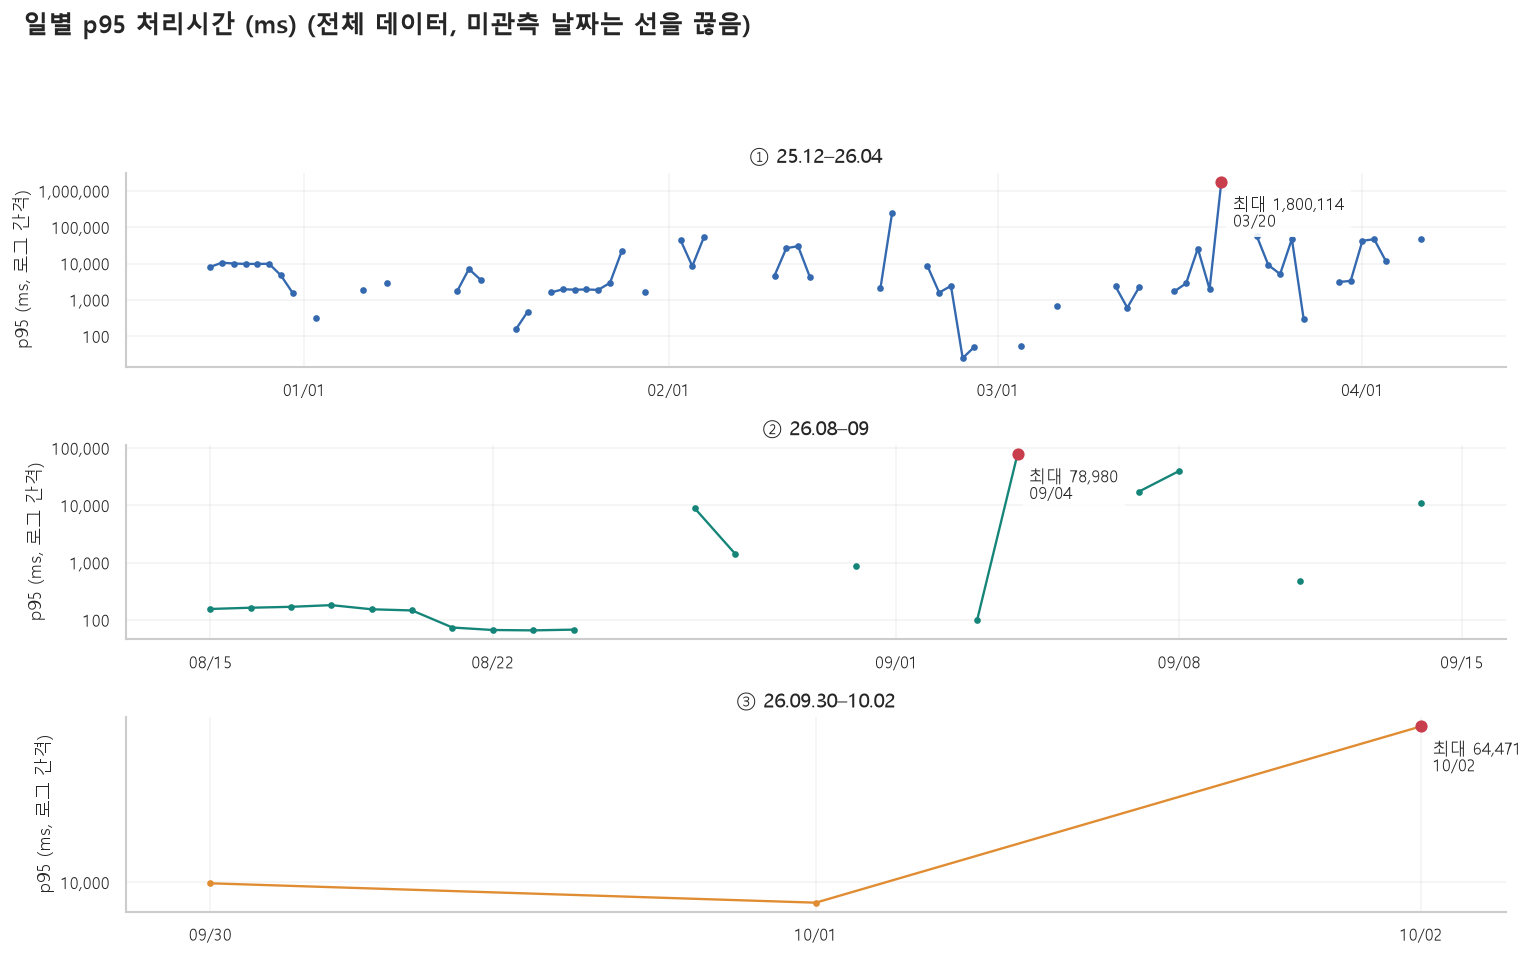

**실제 결과**

- ① 25.12–26.04: 관측 59일, 최대 1,800,114 (2026-03-20).
- ② 26.08–09: 관측 19일, 최대 78,980 (2026-09-04).
- ③ 26.09.30–10.02: 관측 3일, 최대 64,471 (2026-10-02).

**의미**: 건수·p95는 로그 눈금으로 작은 기간도 읽을 수 있게 했고, 실패율은 동일한 0–100% 범위로 표시했습니다. 수집되지 않은 날짜는 0이 아니라 미관측입니다. 날짜별 p95는 관측 건수가 적으면 불안정합니다.

**모델 개발에 반영**: 시간대·요일·업무량을 조건으로 한 기준선과 지연/실패 동시 변화를 검토합니다. 건수 증가만으로 장애를 판정하지 않습니다.

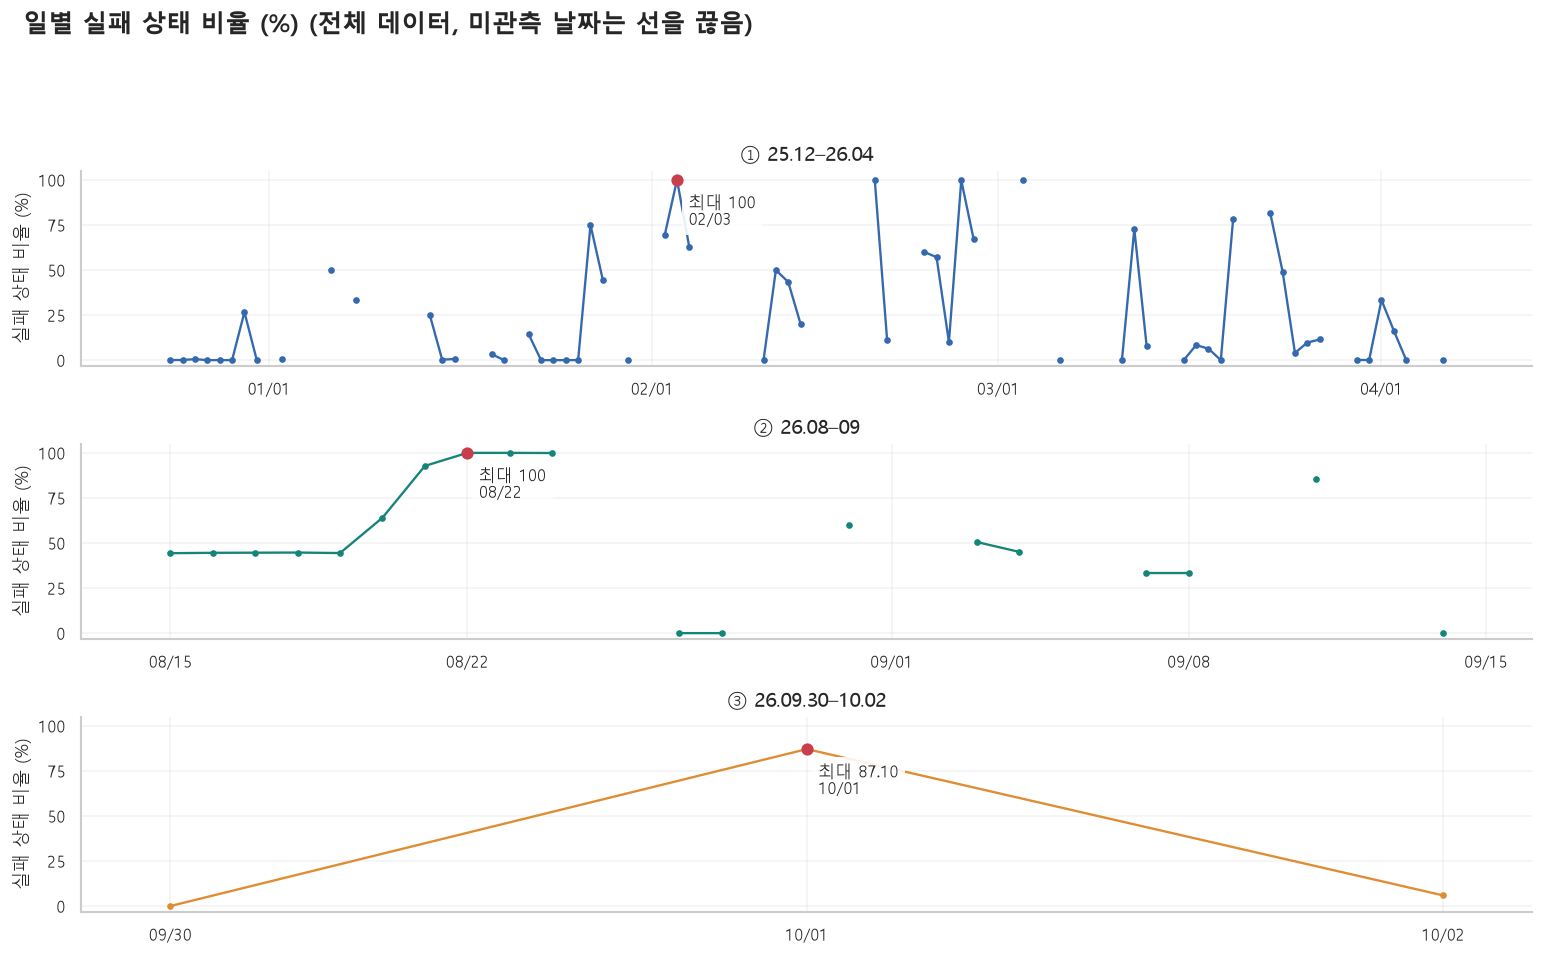

**실제 결과**

- ① 25.12–26.04: 관측 59일, 최대 100 (2026-02-03).
- ② 26.08–09: 관측 19일, 최대 100 (2026-08-22).
- ③ 26.09.30–10.02: 관측 3일, 최대 87.10 (2026-10-01).

**의미**: 건수·p95는 로그 눈금으로 작은 기간도 읽을 수 있게 했고, 실패율은 동일한 0–100% 범위로 표시했습니다. 수집되지 않은 날짜는 0이 아니라 미관측입니다. 날짜별 p95는 관측 건수가 적으면 불안정합니다.

**모델 개발에 반영**: 시간대·요일·업무량을 조건으로 한 기준선과 지연/실패 동시 변화를 검토합니다. 건수 증가만으로 장애를 판정하지 않습니다.

rows  observed_days  rows_per_observed_day
source_period     month                                                 
25년12월24일-26년4월6일 2025-12  1280498              8              160062.25
                  2026-01    25194             16                1574.62
                  2026-02   311074             14               22219.57
                  2026-03   151221             17                8895.35
                  2026-04       67              4                  16.75
26년8월15일-26년9월14일 2026-08   211145             13               16241.92
                  2026-09     2236              6                 372.67
26년9월30일-26년10월2일 2026-09    27051              1               27051.00
                  2026-10      217              2                 108.50

In [12]:
plot_period_timeseries(daily, "p95_ms", "일별 p95 처리시간 (ms)")
plot_period_timeseries(daily, "failure_pct", "일별 실패 상태 비율 (%)")
monthly = daily.assign(month=daily["bin"].dt.to_period("M").astype(str)).groupby(
    ["source_period", "month"], observed=True).agg(rows=("rows", "sum"), observed_days=("bin", "size"))
monthly["rows_per_observed_day"] = monthly["rows"] / monthly["observed_days"]
display(monthly.round(2))


### 4.1 요일·시간대 패턴

요일별 관측 날짜 수로 정규화한 시간대별 로그량을 봅니다. 아래 0은 관측된 날짜의
해당 시간대에서 발견된 행이 없다는 뜻이며, 수집이 완전했다는 보장은 아닙니다.
야간·주말이라는 이유만으로 이상으로 판정하지 않습니다.

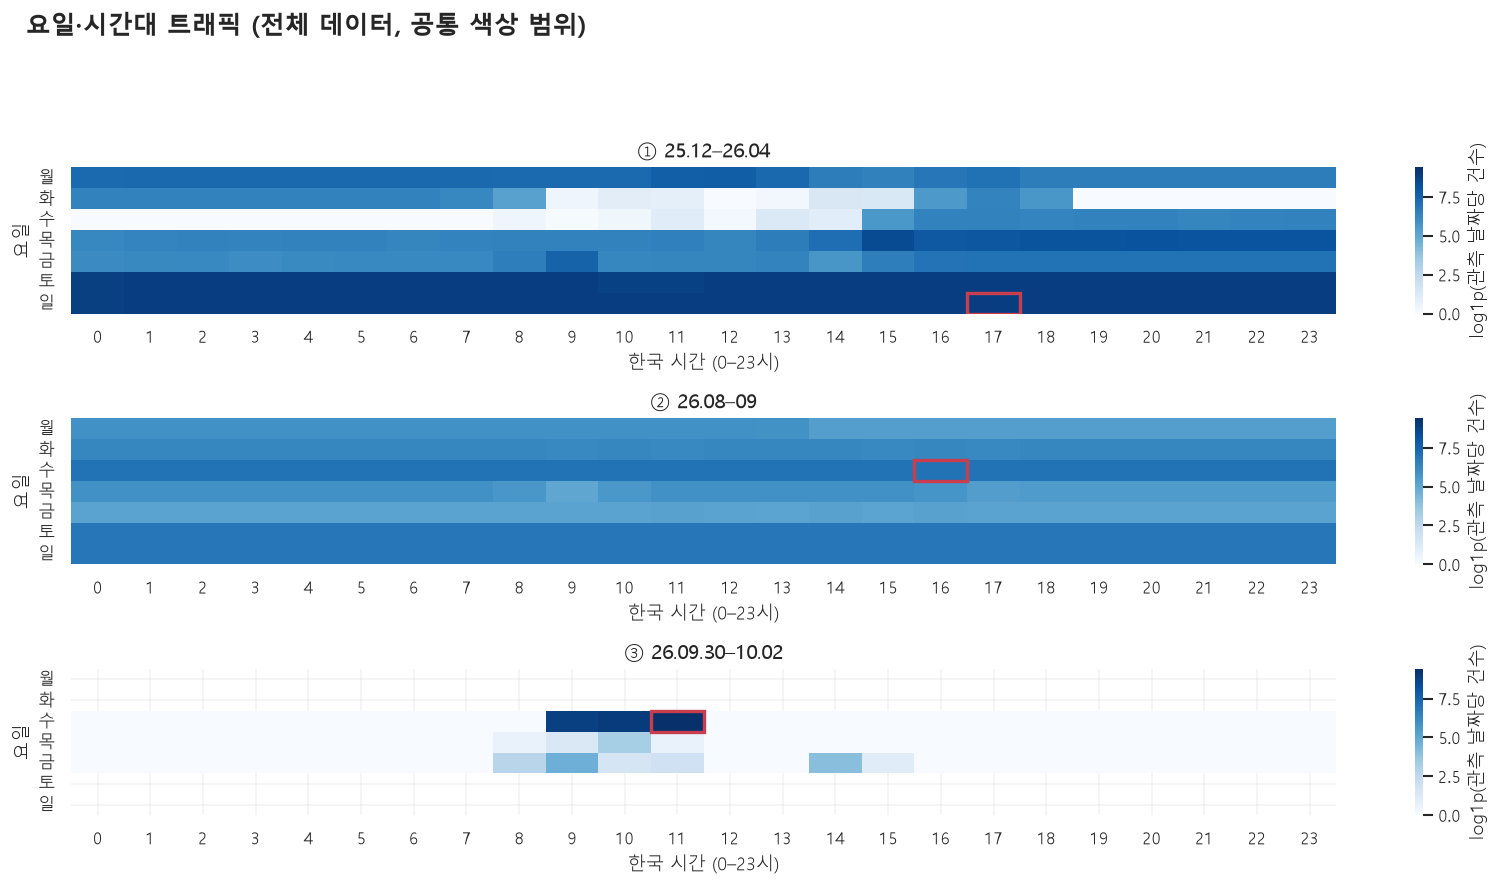

**실제 결과**

- ① 25.12–26.04: 최다 시간대 일요일 17시, 관측 날짜당 7,100.0건. 빨간 테두리로 표시했습니다.
- ② 26.08–09: 최다 시간대 수요일 16시, 관측 날짜당 1,082.0건. 빨간 테두리로 표시했습니다.
- ③ 26.09.30–10.02: 최다 시간대 수요일 11시, 관측 날짜당 12,113.0건. 빨간 테두리로 표시했습니다.

**의미**: 흰색은 해당 요일의 관측 날짜가 없다는 뜻입니다. 파란색 농도는 모든 기간에 같은 로그 색상 범위를 사용합니다. 0건인 칸도 수집이 완전했다는 증거는 아닙니다.

**모델 개발에 반영**: 야간/주말을 무조건 이상으로 취급하지 않고 관측된 주기 패턴을 시간 피처 또는 계절성 기준선에 반영합니다.

In [13]:
plot_hour_pattern(df)


### 4.2 과거 24시간 기준 트래픽 급증·급감 후보

현재 시각을 제외한 과거 24시간의 중앙값/MAD를 기준으로 합니다.
기간별 기준선을 다시 시작하고 빈 시간 구간은 결측으로 둡니다.
이력 6개 미만 또는 MAD=0이면 점수를 산출하지 않습니다.
이는 점검용 규칙이며 계절성 모델이나 확정된 이상 라벨이 아닙니다.

,bins,observed_bins,comparable_bins,candidate_bins
source_period,,,,
25년12월24일-26년4월6일,2471,396,250,54
26년8월15일-26년9월14일,735,258,14,5
26년9월30일-26년10월2일,55,13,0,0


,bin,rows,known_status,failures,median_ms,p95_ms,failure_pct,volume_robust_z,reference_available,candidate,source_period,absolute_z
2333,2026-03-31 15:00:00,5.0,5.0,0.0,344.0,20008.00,0.000000,-2041.150810,True,True,25년12월24일-26년4월6일,2041.150810
2328,2026-03-31 10:00:00,5.0,5.0,1.0,226.0,350.60,20.000000,-1718.381873,True,True,25년12월24일-26년4월6일,1718.381873
795,2026-01-26 13:00:00,1.0,1.0,1.0,511.0,511.00,100.000000,-419.281425,True,True,25년12월24일-26년4월6일,419.281425
2334,2026-03-31 16:00:00,2795.0,2795.0,3.0,2584.0,3093.00,0.107335,-260.417813,True,True,25년12월24일-26년4월6일,260.417813
141,2025-12-30 07:00:00,8.0,8.0,3.0,444.0,6923.10,37.500000,-222.032353,True,True,25년12월24일-26년4월6일,222.032353
2336,2026-03-31 18:00:00,3250.0,3250.0,0.0,2561.0,3159.00,0.000000,-216.720219,True,True,25년12월24일-26년4월6일,216.720219
123,2025-12-29 13:00:00,7134.0,7134.0,2.0,7790.0,10026.35,0.028035,-213.861494,True,True,25년12월24일-26년4월6일,213.861494
2326,2026-03-31 08:00:00,2022.0,2022.0,1.0,2687.0,7293.90,0.049456,-150.403673,True,True,25년12월24일-26년4월6일,150.403673
127,2025-12-29 17:00:00,7770.0,7770.0,0.0,7957.0,10028.55,0.000000,-147.135890,True,True,25년12월24일-26년4월6일,147.135890
126,2025-12-29 16:00:00,8332.0,8332.0,1.0,7577.5,9954.00,0.012002,-145.460693,True,True,25년12월24일-26년4월6일,145.460693


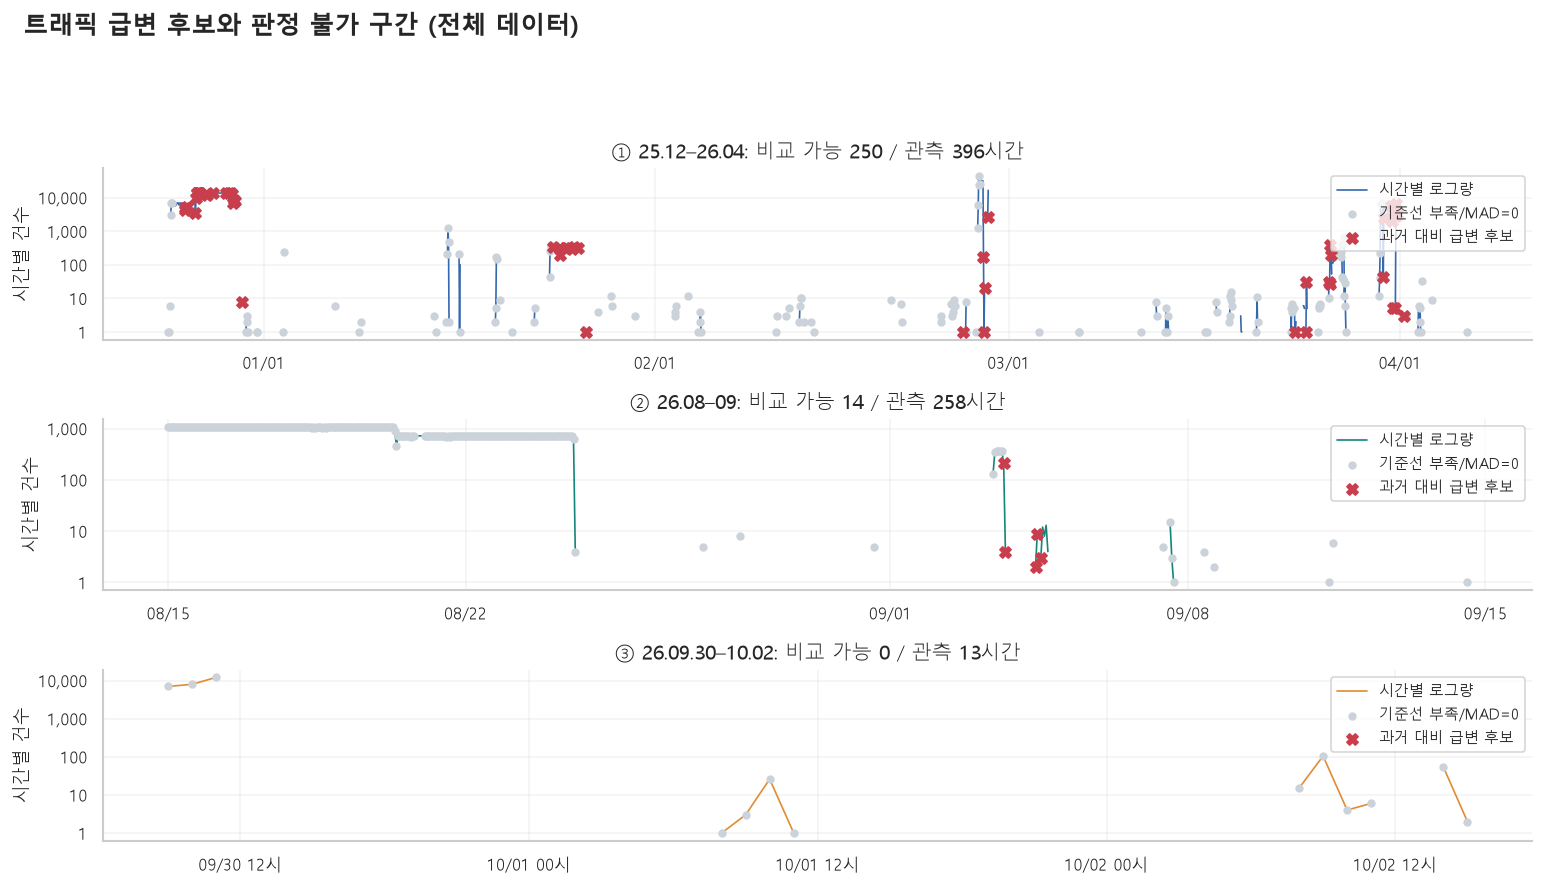

**실제 결과**

- ① 25.12–26.04: 기준선 계산 가능 250시간, 후보 54시간, 기준선 없는 관측 146시간.
- ② 26.08–09: 기준선 계산 가능 14시간, 후보 5시간, 기준선 없는 관측 244시간.
- ③ 26.09.30–10.02: 기준선 계산 가능 0시간, 후보 0시간, 기준선 없는 관측 13시간.

**의미**: 빨간 X는 과거 24시간 로그량 중앙값/MAD 대비 급변 후보입니다. 회색 점은 정상 판정이 아니라 이력 부족 또는 MAD=0으로 비교할 수 없는 관측입니다.

**모델 개발에 반영**: 후보 수와 함께 평가 가능한 구간의 비율을 보고합니다. 짧은 최신 기간에서 후보 0개가 나와도 정상이라고 결론 내리지 않습니다.

In [14]:
traffic_candidates = hourly_history_candidates(hourly)
display(traffic_candidates.groupby("source_period", observed=True).agg(
    bins=("bin", "size"), observed_bins=("rows", "count"),
    comparable_bins=("reference_available", "sum"), candidate_bins=("candidate", "sum")))
display(traffic_candidates.loc[traffic_candidates["candidate"]].assign(
    absolute_z=lambda x: x["volume_robust_z"].abs()).nlargest(15, "absolute_z"))
plot_traffic_candidates(traffic_candidates)


## 5. 상태·업무·처리 경로 분포

합계가 큰 기간이 통합 분포를 지배하므로 기간별 상태 비율도 함께 확인합니다.
새로운 경로는 업무 변경일 수 있으며 빈도가 낮다는 이유만으로 이상으로 보지 않습니다.

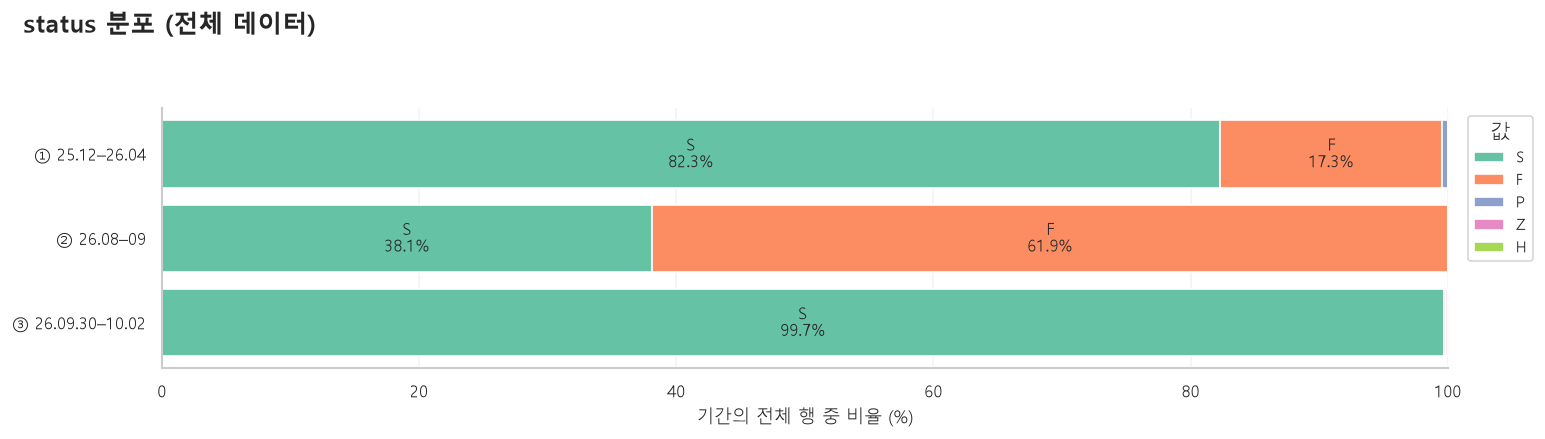

**실제 결과**

- ① 25.12–26.04: 최빈값 S, 1,454,528건 (82.27%).
- ② 26.08–09: 최빈값 F, 132,036건 (61.88%).
- ③ 26.09.30–10.02: 최빈값 S, 27,180건 (99.68%).

**의미**: 기간별 막대의 길이를 100%로 맞췄기 때문에 규모가 아니라 값의 구성 차이를 비교합니다. 처리 건수의 의미·단위는 어댑터마다 다를 수 있습니다.

**모델 개발에 반영**: 연속형 정규분포를 가정하지 않고 범주형/카운트 특성을 반영합니다. 기간·업무 구성이 다른데 공통 IQR을 적용하면 정상 값도 대량 경보가 될 수 있습니다.

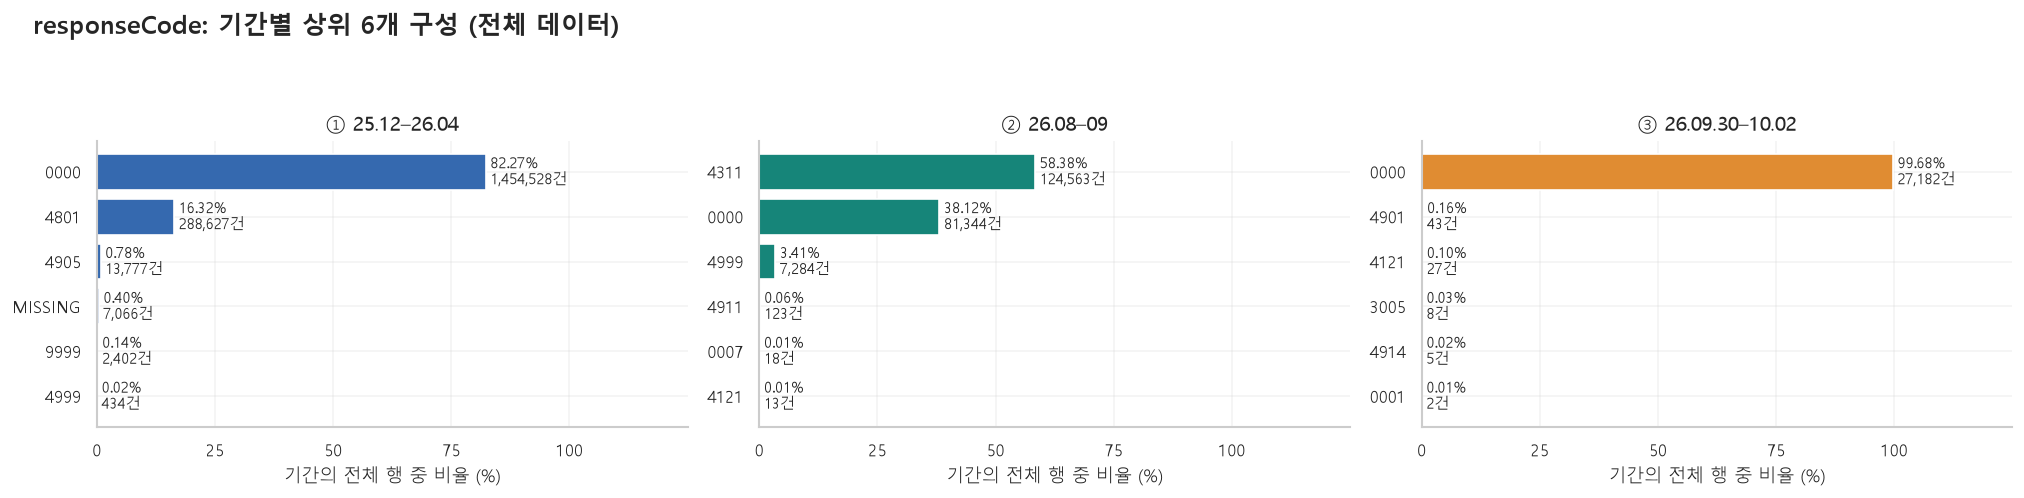

**실제 결과**

- ① 25.12–26.04: 최빈 0000가 82.27%, 상위 6개 합계 99.93%.
- ② 26.08–09: 최빈 4311가 58.38%, 상위 6개 합계 99.98%.
- ③ 26.09.30–10.02: 최빈 0000가 99.68%, 상위 6개 합계 100.00%.

**의미**: 전체 기간을 합산한 순위 대신 각 기간의 상위 범주를 따로 보여줍니다. 업무 구성이나 어댑터 역할이 바뀌면 처리시간과 실패율의 정상 기준도 바뀔 수 있습니다.

**모델 개발에 반영**: 범주별 정상 기준선과 신규 범주 감시를 검토합니다. 상태와 응답코드는 사후 해석용이며 실패 상태 자체를 비지도 모델의 정답으로 사용하지 않습니다.

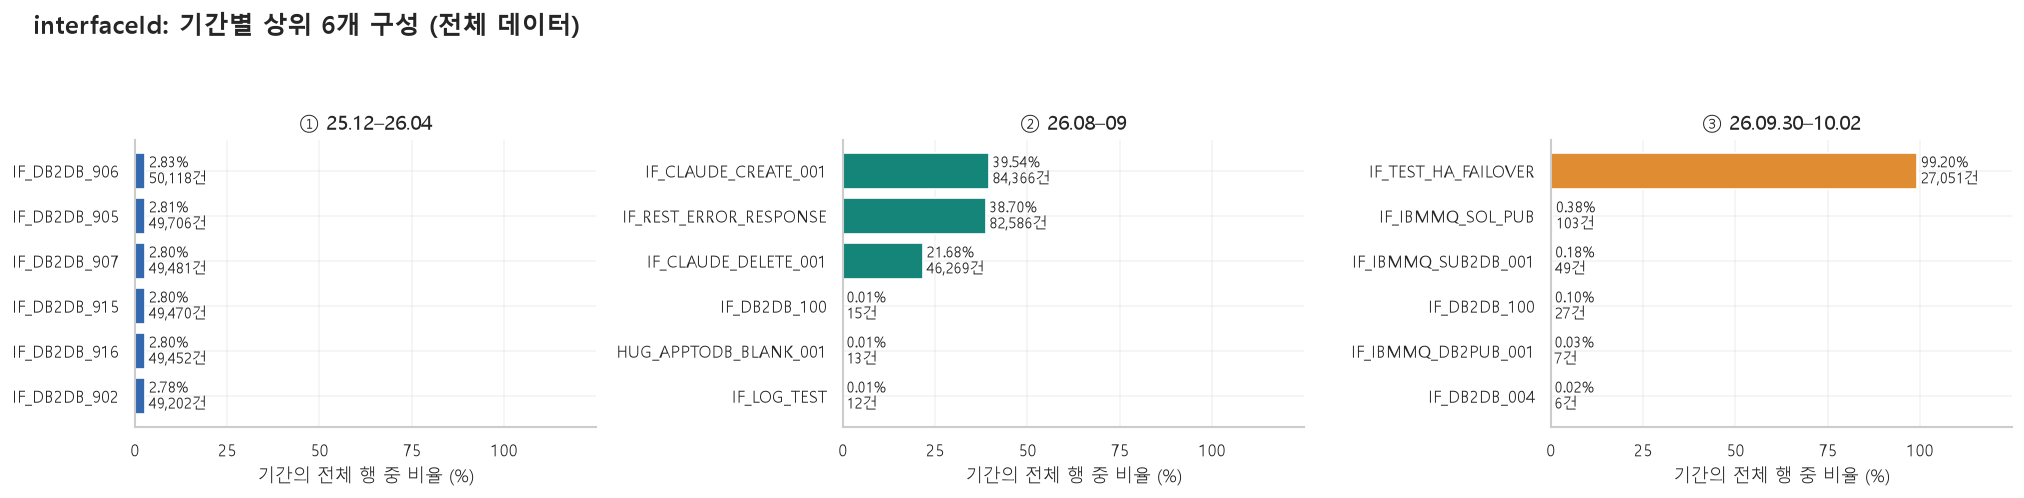

**실제 결과**

- ① 25.12–26.04: 최빈 IF_DB2DB_906가 2.83%, 상위 6개 합계 16.82%.
- ② 26.08–09: 최빈 IF_CLAUDE_CREATE_001가 39.54%, 상위 6개 합계 99.94%.
- ③ 26.09.30–10.02: 최빈 IF_TEST_HA_FAILOVER가 99.20%, 상위 6개 합계 99.91%.

**의미**: 전체 기간을 합산한 순위 대신 각 기간의 상위 범주를 따로 보여줍니다. 업무 구성이나 어댑터 역할이 바뀌면 처리시간과 실패율의 정상 기준도 바뀔 수 있습니다.

**모델 개발에 반영**: 범주별 정상 기준선과 신규 범주 감시를 검토합니다. 상태와 응답코드는 사후 해석용이며 실패 상태 자체를 비지도 모델의 정답으로 사용하지 않습니다.

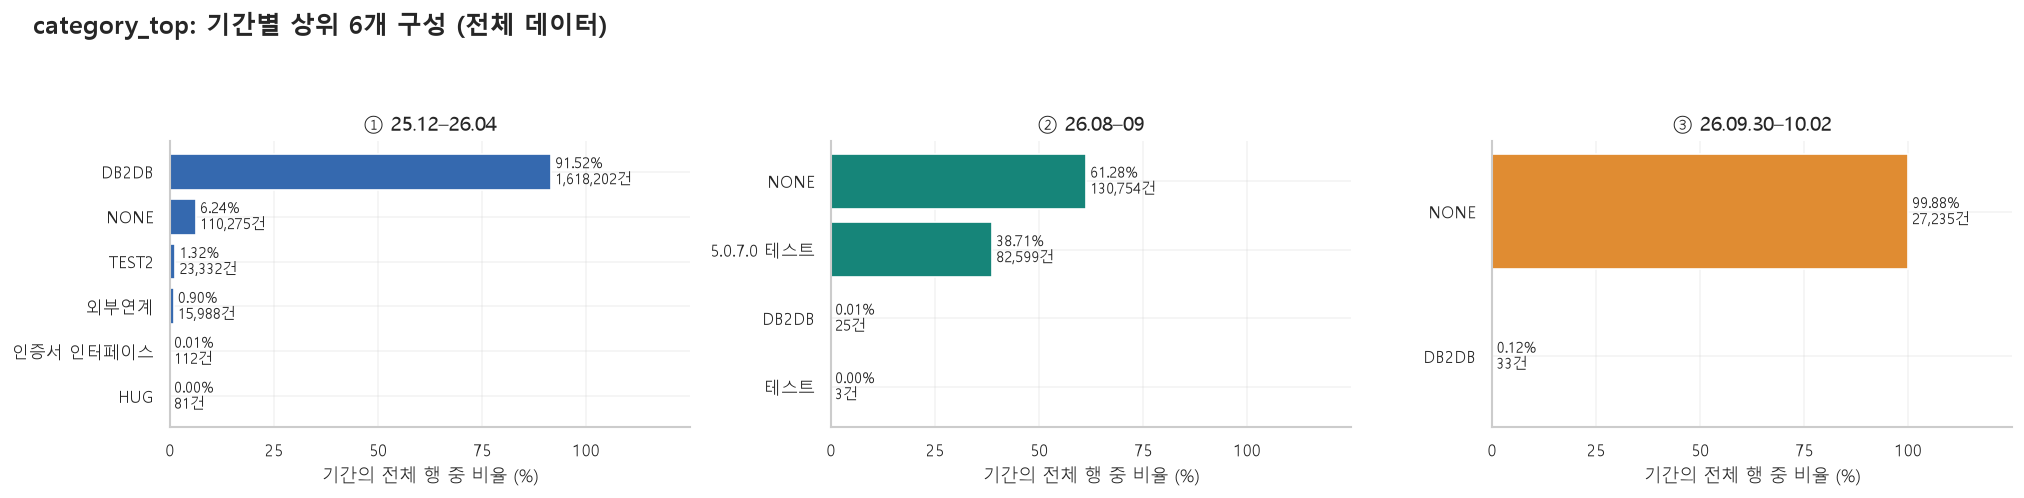

**실제 결과**

- ① 25.12–26.04: 최빈 DB2DB가 91.52%, 상위 6개 합계 100.00%.
- ② 26.08–09: 최빈 NONE가 61.28%, 상위 4개 합계 100.00%.
- ③ 26.09.30–10.02: 최빈 NONE가 99.88%, 상위 2개 합계 100.00%.

**의미**: 전체 기간을 합산한 순위 대신 각 기간의 상위 범주를 따로 보여줍니다. 업무 구성이나 어댑터 역할이 바뀌면 처리시간과 실패율의 정상 기준도 바뀔 수 있습니다.

**모델 개발에 반영**: 범주별 정상 기준선과 신규 범주 감시를 검토합니다. 상태와 응답코드는 사후 해석용이며 실패 상태 자체를 비지도 모델의 정답으로 사용하지 않습니다.

status,F,H,P,S,Z
source_period,,,,,
25년12월24일-26년4월6일,17.32,0.00,0.4,82.27,0.01
26년8월15일-26년9월14일,61.88,0.00,0.0,38.12,0.00
26년9월30일-26년10월2일,0.16,0.01,0.0,99.68,0.16


rows  median_ms  \
source_period     route_key                                               
25년12월24일-26년4월6일 TSC → HUB → SOL                    1642352     5805.0   
26년8월15일-26년9월14일 HUB → HUB → HUB                     213277       58.0   
25년12월24일-26년4월6일 SOL → HUB → SOL                      60454        4.0   
26년9월30일-26년10월2일 SOL → HUB → SOL                      27229     5984.0   
25년12월24일-26년4월6일 TSC → DIRECT → SOL                   25363     1408.0   
                  HUB → HUB → HUB                      24888        6.0   
                  TSC → HUB → TSC                      13312        4.0   
                  TSC → HUB → HUB                       1165        4.0   
                  SOL → DIRECT → TSC                     288       93.5   
                  SOL → HUB → TSC                        152     1276.0   
26년8월15일-26년9월14일 TSC → HUB → SOL                         60     6964.0   
26년9월30일-26년10월2일 TSC → HUB → SOL                         36     7443.0   
26년8월15일-26년9월14일 SOL → HUB → SOL                         33      705.0   
25년12월24일-26년4월6일 TSC → HUB → SAP                         25     2851.0   
                  TSC → HUB → SSCH                        22     1483.5   
                  HUB → DIRECT → HUB                      12       70.0   
                  SAP → HUB → SOL                          9     2217.0   
26년8월15일-26년9월14일 HUG_TEST → HUB → HUG_TEST                4    28790.0   
                  TSC → HUB → HUB                          3      553.0   
25년12월24일-26년4월6일 MISSING → - → MISSING                    3      151.0   
                  THUB → THUB → THUB                       2    20155.0   
                  PATCH_SERVER → HUB → PATCH_SERVER        2      764.5   
                  SSCH → HUB → SSCH                        2      614.5   
26년8월15일-26년9월14일 TSC → HUB → TSC                          2     1324.0   
26년9월30일-26년10월2일 SOL → SOL → SOL                          2      232.0   

                                                        p95_ms  
source_period     route_key                                     
25년12월24일-26년4월6일 TSC → HUB → SOL                      9719.00  
26년8월15일-26년9월14일 HUB → HUB → HUB                       159.00  
25년12월24일-26년4월6일 SOL → HUB → SOL                        21.00  
26년9월30일-26년10월2일 SOL → HUB → SOL                      9933.40  
25년12월24일-26년4월6일 TSC → DIRECT → SOL                   2349.00  
                  HUB → HUB → HUB                      7060.00  
                  TSC → HUB → TSC                        28.00  
                  TSC → HUB → HUB                        16.00  
                  SOL → DIRECT → TSC                  47012.45  
                  SOL → HUB → TSC                    835208.15  
26년8월15일-26년9월14일 TSC → HUB → SOL                     33624.95  
26년9월30일-26년10월2일 TSC → HUB → SOL                      7832.25  
26년8월15일-26년9월14일 SOL → HUB → SOL                     51796.20  
25년12월24일-26년4월6일 TSC → HUB → SAP                     10800.20  
                  TSC → HUB → SSCH                    30047.95  
                  HUB → DIRECT → HUB                    145.05  
                  SAP → HUB → SOL                      5058.80  
26년8월15일-26년9월14일 HUG_TEST → HUB → HUG_TEST           40504.20  
                  TSC → HUB → HUB                     54364.90  
25년12월24일-26년4월6일 MISSING → - → MISSING                 261.70  
                  THUB → THUB → THUB                  37823.80  
                  PATCH_SERVER → HUB → PATCH_SERVER    1423.75  
                  SSCH → HUB → SSCH                    1067.65  
26년8월15일-26년9월14일 TSC → HUB → TSC                      1476.10  
26년9월30일-26년10월2일 SOL → SOL → SOL                       300.40

**실제 결과**

- 경로 표는 전체 데이터 기준 로그량 상위 25개이며, p95는 각 경로 유효 처리시간의 95% 분위수입니다.

**의미**: 로그량이 많은 경로와 느린 경로는 다를 수 있습니다. 기간·업무가 바뀌면 경로의 정상 지연도 달라질 수 있습니다.

**모델 개발에 반영**: 경로/업무별 지연 기준선을 전체 기간 모델과 비교합니다.

In [15]:
df["route_key"] = (text(df["startChannelId"]) + " → " + text(df["processHubId"]) + " → " + text(df["endChannelId"])).astype("category")
df["category_top"] = text(df["categoryName"]).str.split(">").str[0].str.strip().astype("category")
plot_categories(df, ["status", "responseCode", "interfaceId", "category_top"])
display(pd.crosstab(df["source_period"], text(df["status"]), normalize="index").mul(100).round(2))
route_summary = df.groupby(["source_period", "route_key"], observed=True).agg(
    rows=("transactionId", "size"), median_ms=("duration_ms", "median"), p95_ms=("duration_ms", lambda s: s.quantile(.95)))
display(route_summary.sort_values("rows", ascending=False).head(25))
note("경로 표는 전체 데이터 기준 로그량 상위 25개이며, p95는 각 경로 유효 처리시간의 95% 분위수입니다.",
     "로그량이 많은 경로와 느린 경로는 다를 수 있습니다. 기간·업무가 바뀌면 경로의 정상 지연도 달라질 수 있습니다.",
     "경로/업무별 지연 기준선을 전체 기간 모델과 비교합니다.")


## 6. 전체 IQR와 업무 그룹별 처리시간 기준선

전체 IQR은 여러 업무·기간의 분포를 섞으므로 참고용입니다.
`source_period + interfaceId`별 로그 처리시간의 중앙값/MAD 기준을 함께 봅니다.
유효 처리시간 30건 이상, MAD>0인 그룹에서만 상대적인 지연 후보를 계산합니다.
MAD=0/표본 부족은 판정 불가로 남깁니다. 이 전체 기간 EDA 기준선은
뒤의 시간 분리 모델 입력에 사용하지 않아 미래 정보 누출을 방지합니다.

In [16]:
iqr_table, iqr_flags = iqr_summary(df, ['duration_ms', 'processCount', 'retryCount'])
df["iqr_candidate"] = iqr_flags.any(axis=1)
display(iqr_table.round(3))
context_profile, context_result = contextual_duration(df, "interfaceId")
df[context_result.columns] = context_result
display(df.groupby("source_period", observed=True).agg(
    rows=("transactionId", "size"), iqr_candidates=("iqr_candidate", "sum"),
    context_comparable=("context_comparable", "sum"), context_candidates=("context_candidate", "sum")))
display(context_profile.sort_values("support", ascending=False).head(15))


,feature,q1,q3,IQR,candidate_count,candidate_pct
0,duration_ms,144.0,7514.0,7370.0,6766,0.337
1,processCount,2.0,2.0,0.0,362740,18.058
2,retryCount,0.0,0.0,0.0,0,0.000


,rows,iqr_candidates,context_comparable,context_candidates
source_period,,,,
25년12월24일-26년4월6일,1768054,128167,1759424,89080
26년8월15일-26년9월14일,213381,213344,213221,7256
26년9월30일-26년10월2일,27268,27224,27203,12380


support    median       MAD
source_period     interfaceId                                        
26년8월15일-26년9월14일 IF_CLAUDE_CREATE_001      84366  4.204693  0.161641
                  IF_REST_ERROR_RESPONSE    82586  3.828641  0.115069
25년12월24일-26년4월6일 IF_DB2DB_906              50081  8.543446  0.462899
                  IF_DB2DB_905              49665  8.575273  0.453665
                  IF_DB2DB_907              49448  8.561019  0.457524
                  IF_DB2DB_915              49434  8.572912  0.460628
                  IF_DB2DB_916              49413  8.567506  0.450341
                  IF_DB2DB_902              49167  8.575085  0.445789
                  IF_DB2DB_914              48934  8.590444  0.442324
                  IF_DB2DB_917              48902  8.571492  0.449140
                  IF_DB2DB_904              48886  8.583355  0.441378
                  IF_DB2DB_908              48876  8.568646  0.441412
                  IF_DB2DB_901              48764  8.572249  0.449470
                  IF_DB2DB_919              48764  8.574518  0.453335
                  IF_DB2DB_909              48652  8.569216  0.456044

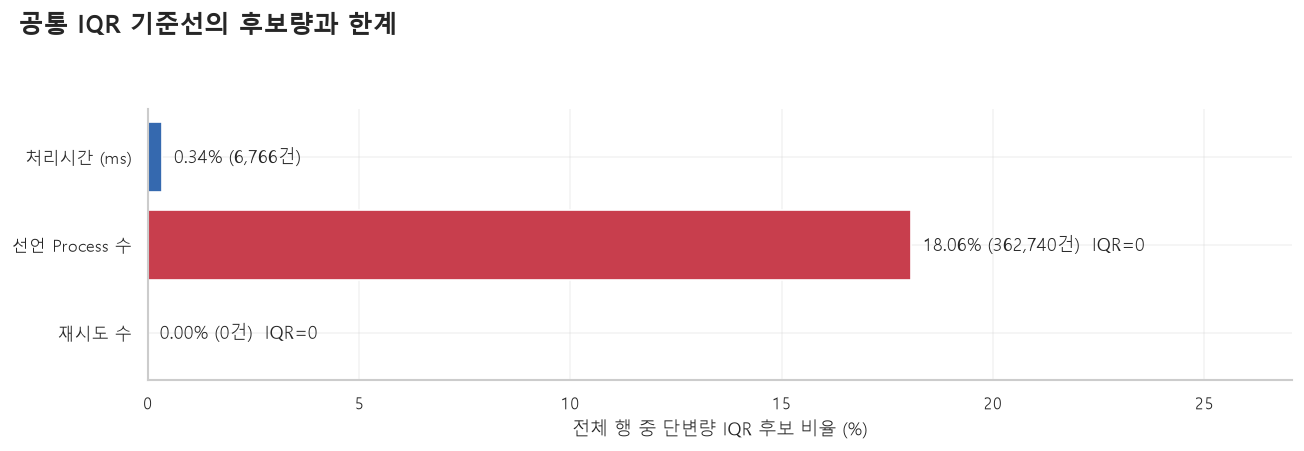

**실제 결과**

- IQR=0인 변수: processCount, retryCount. 처리시간 외 카운트 변수는 정상 최빈값에서 벗어나기만 해도 후보가 될 수 있습니다.

**의미**: IQR=0이면 Q1과 Q3가 같아 정상 범위를 사실상 한 점으로 축소합니다. 이때 큰 후보량은 탐지 성능보다 혼합된 이산 분포와 기준선의 한계를 보여줍니다.

**모델 개발에 반영**: 전체 IQR 후보를 정답으로 학습하지 않습니다. 카운트는 업무별 허용값·범주형 표현을 검토하고 처리시간은 그룹별 기준선과 비교합니다.

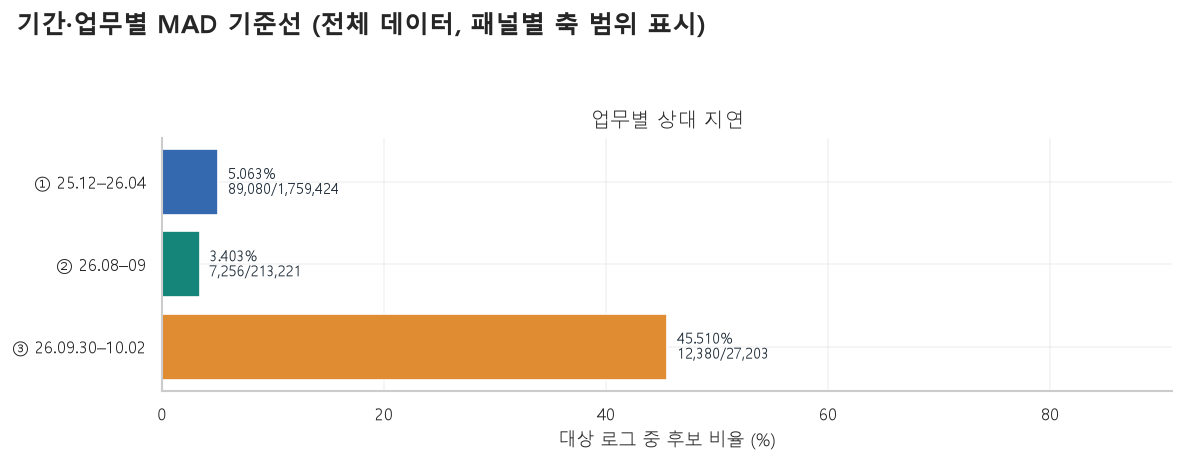

**실제 결과**

- ① 25.12–26.04 / 업무별 상대 지연: 89,080 / 1,759,424건 (5.063%).
- ② 26.08–09 / 업무별 상대 지연: 7,256 / 213,221건 (3.403%).
- ③ 26.09.30–10.02 / 업무별 상대 지연: 12,380 / 27,203건 (45.510%).

**의미**: 분모는 각 규칙의 비교 가능한 로그입니다(별도 조건이 없는 규칙은 기간 전체 행). 서로 다른 규칙의 후보는 중복될 수 있어 합산하면 안 됩니다. 후보 0건과 비교 불가는 다릅니다.

**모델 개발에 반영**: 낮은 비율도 실제 건수로 확인해 검토 대상을 정합니다. 정합성 규칙은 비지도 모델 점수와 별도로 표시하며 확정 장애 라벨로 사용하지 않습니다.

**실제 결과**

- ① 25.12–26.04: 그룹 기준선으로 비교 불가 8,630건.
- ② 26.08–09: 그룹 기준선으로 비교 불가 160건.
- ③ 26.09.30–10.02: 그룹 기준선으로 비교 불가 65건.

**의미**: 업무별 상대 지연 후보가 많으면 그룹 내부 다중 모드 또는 매우 작은 MAD 때문에 규칙이 민감한지도 확인해야 합니다. MAD=0/표본 부족/처리시간 결측은 정상 0점이 아닙니다.

**모델 개발에 반영**: 그룹별 지연 분포를 다시 살피고 최소 분산·운영 허용 지연 등 기준선을 보완합니다. 이 전체기간 EDA 기준선은 시간 분리 모델의 입력에 사용하지 않습니다.

In [17]:
plot_statistical_candidates(df, iqr_table)


In [18]:
context_by_entity = df.groupby(["source_period", "interfaceId"], observed=True).agg(
    rows=("transactionId", "size"), comparable=("context_comparable", "sum"), candidates=("context_candidate", "sum"))
context_by_entity["candidate_pct_of_comparable"] = context_by_entity["candidates"].div(
    context_by_entity["comparable"].replace(0, np.nan)).mul(100)
display(context_by_entity.loc[context_by_entity["comparable"].ge(30)].sort_values(
    "candidate_pct_of_comparable", ascending=False).head(20))
note("업무별 후보 비율의 분모는 전체 업무 행 수가 아니라 유효 처리시간·충분한 표본·MAD>0을 충족하는 비교 가능 행 수입니다.",
     "높은 비율은 지연 외에 업무 내부의 여러 실행 모드나 작은 MAD 때문에 발생할 수 있습니다.",
     "후보 비율 상위 업무를 먼저 검토하되 표본 수와 정상 실행 정의를 함께 확인합니다.")


rows  comparable  candidates  \
source_period     interfaceId                                          
26년9월30일-26년10월2일 IF_TEST_HA_FAILOVER  27051       27051       12367   
                  IF_IBMMQ_SUB2DB_001     49          49          13   
25년12월24일-26년4월6일 SERVICE_DELAY_TEST    2255        2255         444   
                  IF_DB2DB_106           117         117          20   
                  IF_DB2DB_103           767         766         126   
                  IF_DB2DB_007            37          36           5   
                  IF_A2A_FILE_201         36          36           5   
                  IF_DB2DB_9xx_DELETE    154         149          18   
                  IF_SUB2DB_103         3316        3265         357   
                  IF_DB2DB_936         27110       27073        2728   
                  IF_A2A_FILE_208         30          30           3   
                  IF_DB2DB_948          2004        1966         195   
                  IF_A2A_FILE_202         32          32           3   
                  IF_AP2TCP_002        15988       15484        1416   
                  IF_DB2DB_937         26862       26822        2393   
                  IF_DB2DB_932         26713       26679        2326   
                  IF_DB2DB_101           257         257          22   
                  IF_AP2TCP_000        28375       27619        2351   
                  Handler_TEST            49          47           4   
                  IF_AP2TCP_001        14479       14189        1179   

                                       candidate_pct_of_comparable  
source_period     interfaceId                                       
26년9월30일-26년10월2일 IF_TEST_HA_FAILOVER                    45.717349  
                  IF_IBMMQ_SUB2DB_001                    26.530612  
25년12월24일-26년4월6일 SERVICE_DELAY_TEST                     19.689579  
                  IF_DB2DB_106                           17.094017  
                  IF_DB2DB_103                           16.449086  
                  IF_DB2DB_007                           13.888889  
                  IF_A2A_FILE_201                        13.888889  
                  IF_DB2DB_9xx_DELETE                    12.080537  
                  IF_SUB2DB_103                          10.934150  
                  IF_DB2DB_936                           10.076460  
                  IF_A2A_FILE_208                        10.000000  
                  IF_DB2DB_948                            9.918616  
                  IF_A2A_FILE_202                         9.375000  
                  IF_AP2TCP_002                           9.144924  
                  IF_DB2DB_937                            8.921781  
                  IF_DB2DB_932                            8.718468  
                  IF_DB2DB_101                            8.560311  
                  IF_AP2TCP_000                           8.512256  
                  Handler_TEST                            8.510638  
                  IF_AP2TCP_001                           8.309254

**실제 결과**

- 업무별 후보 비율의 분모는 전체 업무 행 수가 아니라 유효 처리시간·충분한 표본·MAD>0을 충족하는 비교 가능 행 수입니다.

**의미**: 높은 비율은 지연 외에 업무 내부의 여러 실행 모드나 작은 MAD 때문에 발생할 수 있습니다.

**모델 개발에 반영**: 후보 비율 상위 업무를 먼저 검토하되 표본 수와 정상 실행 정의를 함께 확인합니다.

## 7. 시간·상태·응답코드 정합성

기록 처리시간과 계산 처리시간의 차이는 양쪽 값이 있는 행에서만 비교합니다.
상태/응답코드도 알려진 `S`/`F` 상태와 알려진 코드에서만 비교합니다.
`0000`을 성공 코드로 가정한 점검 규칙이므로 실제 운영 코드 정의와 대조해야 합니다.

In [ ]:
df["duration_mismatch_ms"] = (df["duration_ms"] - df["processTime"]).abs()
df["duration_inconsistent"] = df["duration_mismatch_ms"].gt(1)
code_comparable = df["status"].isin(["S", "F"]) & df["responseCode"].notna()
df["status_code_candidate"] = code_comparable & (
    (df["status"].eq("S") & df["responseCode"].ne("0000")) |
    (df["status"].eq("F") & df["responseCode"].eq("0000")))
df["integrity_candidate"] = df["negative_duration"] | df["duration_inconsistent"] | df["status_code_candidate"]
display(df.groupby("source_period", observed=True).agg(
    rows=("transactionId", "size"), duration_mismatches=("duration_inconsistent", "sum"),
    status_code_candidates=("status_code_candidate", "sum"), negative_duration=("negative_duration", "sum")))
print(f"상태·코드 비교 가능: {code_comparable.sum():,}건")
display(df.loc[df["integrity_candidate"], ["source_period", "transactionId", "status", "responseCode", "duration_ms", "processTime"]].head(15))
df["status_code_comparable"] = code_comparable
df["duration_comparable"] = df[["duration_ms", "processTime"]].notna().all(axis=1)
plot_rule_rates(df, {"duration_inconsistent": "계산/기록 시간 불일치", "status_code_candidate": "상태/응답코드 불일치"},
                {"duration_inconsistent": "duration_comparable", "status_code_candidate": "status_code_comparable"},
                "Transaction 정합성")


## 8. 업무별 도착 간격과 동시 발생

같은 기간·업무 안에서 시간 순으로 정렬해 직전 거래와의 간격을 확인합니다.
기간 사이의 긴 수집 공백을 도착 간격으로 사용하지 않습니다.
0초 간격은 배치·동시 실행일 수도 있으므로 업무별 정상 패턴과 함께 봅니다.

,count,mean,std,min,1%,50%,95%,99%,max
source_period,,,,,,,,,
25년12월24일-26년4월6일,1767689.0,538.343,40961.195,0.000,0.159,10.004,20.068,49.789,7438686.659
26년8월15일-26년9월14일,213334.0,46.091,6138.442,0.278,9.885,10.000,10.024,10.125,1862238.395
26년9월30일-26년10월2일,27256.0,1.624,80.619,0.000,0.000,0.032,0.132,0.302,7107.230


intervals  median_seconds  \
source_period     interfaceId                                         
26년8월15일-26년9월14일 IF_CLAUDE_CREATE_001        84365          10.000   
                  IF_REST_ERROR_RESPONSE      82585          10.000   
25년12월24일-26년4월6일 IF_DB2DB_906                50117          10.005   
                  IF_DB2DB_905                49705          10.006   
                  IF_DB2DB_907                49480          10.006   
                  IF_DB2DB_915                49469          10.004   
                  IF_DB2DB_916                49451          10.002   
                  IF_DB2DB_902                49201          10.003   
                  IF_DB2DB_914                48968          10.006   
                  IF_DB2DB_917                48925          10.005   
                  IF_DB2DB_904                48921          10.006   
                  IF_DB2DB_908                48903          10.004   
                  IF_DB2DB_901                48804          10.002   
                  IF_DB2DB_919                48795          10.009   
                  IF_DB2DB_909                48684          10.007   
                  IF_DB2DB_911                48574          10.006   
                  IF_DB2DB_910                48570          10.006   
                  IF_DB2DB_912                48562          10.007   
                  IF_DB2DB_918                48515          10.009   
                  IF_DB2DB_903                47951          10.004   

                                          zero_gap_pct  
source_period     interfaceId                           
26년8월15일-26년9월14일 IF_CLAUDE_CREATE_001             0.0  
                  IF_REST_ERROR_RESPONSE           0.0  
25년12월24일-26년4월6일 IF_DB2DB_906                     0.0  
                  IF_DB2DB_905                     0.0  
                  IF_DB2DB_907                     0.0  
                  IF_DB2DB_915                     0.0  
                  IF_DB2DB_916                     0.0  
                  IF_DB2DB_902                     0.0  
                  IF_DB2DB_914                     0.0  
                  IF_DB2DB_917                     0.0  
                  IF_DB2DB_904                     0.0  
                  IF_DB2DB_908                     0.0  
                  IF_DB2DB_901                     0.0  
                  IF_DB2DB_919                     0.0  
                  IF_DB2DB_909                     0.0  
                  IF_DB2DB_911                     0.0  
                  IF_DB2DB_910                     0.0  
                  IF_DB2DB_912                     0.0  
                  IF_DB2DB_918                     0.0  
                  IF_DB2DB_903                     0.0

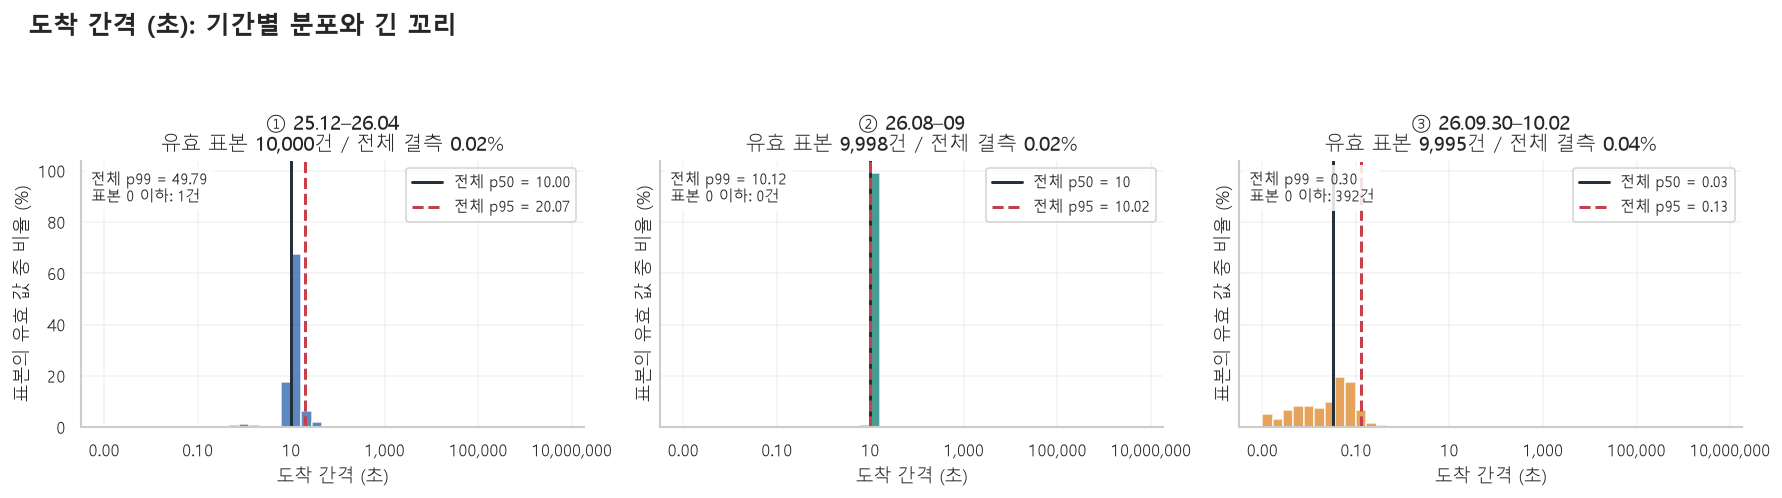

**실제 결과**

- ① 25.12–26.04: 전체 중앙값 10.00, p95 20.07, p99 49.79.
- ② 26.08–09: 전체 중앙값 10, p95 10.02, p99 10.12.
- ③ 26.09.30–10.02: 전체 중앙값 0.03, p95 0.13, p99 0.30.

**의미**: 가로축은 로그 간격이지만 눈금은 실제 단위입니다. 히스토그램은 같은 구간·같은 세로축을 사용하는 균형 표본이며 선과 분위수는 전체 데이터입니다. p95보다 큰 값은 전체 유효 값의 최대 약 5%입니다(동률 제외). 표본에 없는 극단값은 히스토그램 범위 밖일 수 있으며 전체 통계 표에서 확인합니다.

**모델 개발에 반영**: 업무·시간대별 도착 간격을 비교하고 수집 공백/배치 실행을 구분한 뒤 발생률 기준선에 반영합니다.

**실제 결과**

- 0초 도착 간격 1,334건. 각 기간·업무의 첫 거래는 직전 간격이 없으므로 결측입니다.

**의미**: 0초 간격은 배치/동시 실행일 수 있습니다. 긴 간격에는 수집되지 않은 날도 포함될 수 있어 낮은 트래픽을 바로 서비스 중단으로 볼 수 없습니다.

**모델 개발에 반영**: 시간대·업무별 발생률과 수집 상태를 함께 확인한 후 도착 간격 기반 탐지를 설계합니다.

In [20]:
arrivals = df.loc[df["startTime"].notna(), ["source_period", "interfaceId", "startTime"]].sort_values(
    ["source_period", "interfaceId", "startTime"])
arrivals["interarrival_seconds"] = arrivals.groupby(["source_period", "interfaceId"], observed=True)["startTime"].diff().dt.total_seconds()
display(arrivals.groupby("source_period", observed=True)["interarrival_seconds"].describe(percentiles=[.01, .5, .95, .99]).round(3))
display(arrivals.groupby(["source_period", "interfaceId"], observed=True)["interarrival_seconds"].agg(
    intervals="count", median_seconds="median", zero_gap_pct=lambda s: s.dropna().eq(0).mean() * 100).sort_values("intervals", ascending=False).head(20))
arrivals_plot = sample_by_period(arrivals, PLOT_SAMPLE, RANDOM_STATE)
plot_numeric_distributions(arrivals, arrivals_plot, ["interarrival_seconds"])
note(f"0초 도착 간격 {arrivals['interarrival_seconds'].eq(0).sum():,}건. 각 기간·업무의 첫 거래는 직전 간격이 없으므로 결측입니다.",
     "0초 간격은 배치/동시 실행일 수 있습니다. 긴 간격에는 수집되지 않은 날도 포함될 수 있어 낮은 트래픽을 바로 서비스 중단으로 볼 수 없습니다.",
     "시간대·업무별 발생률과 수집 상태를 함께 확인한 후 도착 간격 기반 탐지를 설계합니다.")
del arrivals


## 9. 기간별 분포 변화와 새로운 범주

첫 기간을 기준으로 수치형 PSI와 새로운 업무·경로 비율을 비교합니다.
PSI는 기준 기간의 고정 분위수 구간을 사용하며 0에 가까울수록 분포가 유사합니다.
기준 기간의 범위를 벗어난 값과 상수였던 변수의 새 값도 별도 구간에 집계합니다.
구간 수와 관측 행 수도 함께 확인하며 분위수와 결측률을 같이 비교합니다.
기간 차이는 운영 환경·업무·수집 범위 변화일 수 있어 이상으로 바로 확정하지 않습니다.

,feature,source_period,reference_rows,current_nonmissing,bins,PSI,median,p99,missing_pct
0,duration_ms,25년12월24일-26년4월6일,1760994,1760994,12,0.0000,5458.0,10952.00,0.3993
1,duration_ms,26년8월15일-26년9월14일,1760994,213381,12,10.0313,58.0,398.20,0.0000
2,duration_ms,26년9월30일-26년10월2일,1760994,27268,12,2.8529,5984.0,52072.97,0.0000
3,processCount,25년12월24일-26년4월6일,1768051,1768051,4,0.0000,2.0,3.00,0.0002
4,processCount,26년8월15일-26년9월14일,1768051,213381,4,10.1722,1.0,1.00,0.0000
5,processCount,26년9월30일-26년10월2일,1768051,27268,4,8.0334,1.0,1.00,0.0000
6,retryCount,25년12월24일-26년4월6일,1768054,1768054,3,0.0000,0.0,0.00,0.0000
7,retryCount,26년8월15일-26년9월14일,1768054,213381,3,0.0000,0.0,0.00,0.0000
8,retryCount,26년9월30일-26년10월2일,1768054,27268,3,0.0002,0.0,0.00,0.0000


,feature,source_period,unique_values,new_values,new_value_row_pct
0,interfaceId,25년12월24일-26년4월6일,365,0,0.000
1,interfaceId,26년8월15일-26년9월14일,47,31,99.974
2,interfaceId,26년9월30일-26년10월2일,12,10,99.879
3,route_key,25년12월24일-26년4월6일,19,0,0.000
4,route_key,26년8월15일-26년9월14일,8,3,0.003
5,route_key,26년9월30일-26년10월2일,4,1,0.007
6,category_top,25년12월24일-26년4월6일,14,0,0.000
7,category_top,26년8월15일-26년9월14일,4,1,38.710
8,category_top,26년9월30일-26년10월2일,2,0,0.000


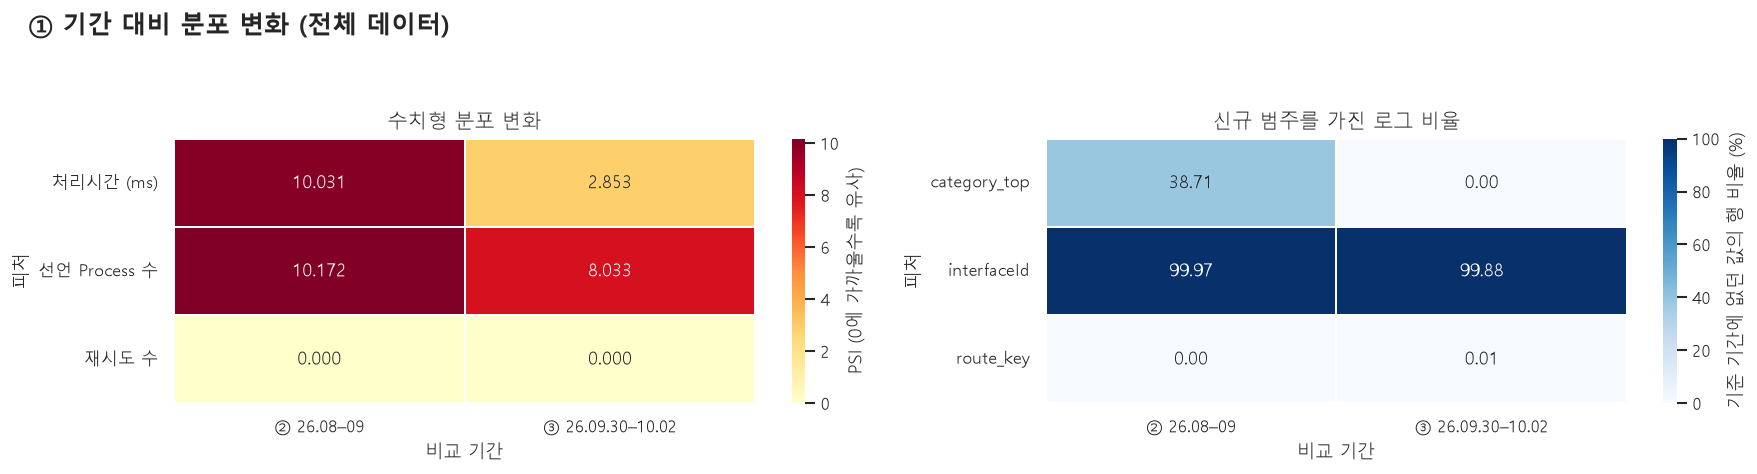

**실제 결과**

- ② 26.08–09 / 선언 Process 수: PSI 10.172.
- ② 26.08–09 / 처리시간 (ms): PSI 10.031.
- ③ 26.09.30–10.02 / 선언 Process 수: PSI 8.033.
- ② 26.08–09 / interfaceId: 기준 기간에 없던 값을 가진 로그 99.97%.

**의미**: 여러 피처와 업무 ID가 함께 바뀌면 처리 방식·업무 구성·수집 범위 변화(도메인 변화)를 우선 의심합니다. PSI는 분포 차이 지표이며 실제 이상 비율이 아닙니다. 상수 피처의 극소 PSI는 표본 크기와 평활화 때문일 수 있습니다.

**모델 개발에 반영**: 전체 기간 공통 모델과 업무/운영 환경별 기준 모델을 비교합니다. 새 범주 로그는 지연·정합성 증거를 함께 검토하며 신규 업무라는 이유만으로 장애로 확정하지 않습니다.

In [21]:
drift_numeric = numeric_drift(df, ['duration_ms', 'processCount', 'retryCount'])
drift_categories = categorical_drift(df, ['interfaceId', 'route_key', 'category_top'])
display(drift_numeric.round(4))
display(drift_categories.round(3))
plot_drift(drift_numeric, drift_categories)


### 9.1 수치 피처 간 중복 정보

긴 꼬리에 강한 Spearman 상관계수를 기간별 균형 표본에서 확인합니다.
강한 상관관계나 전부 결측·상수인 피처는 모델 입력을 검토할 때 참고합니다.

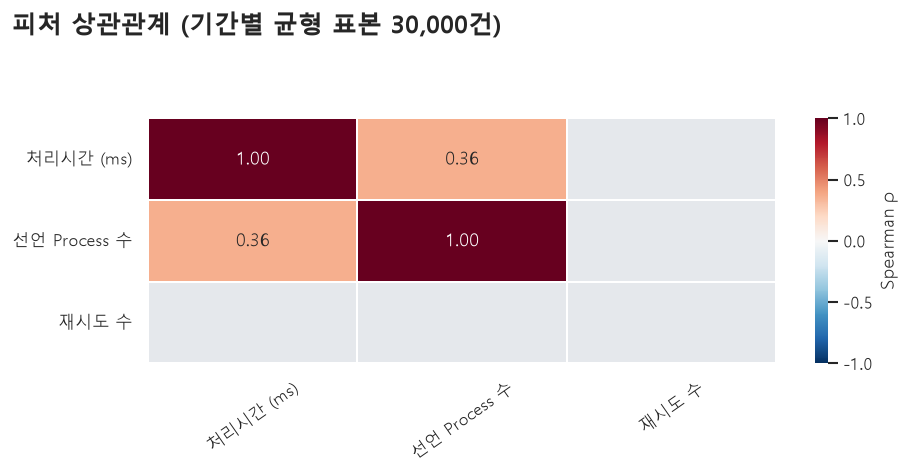

**실제 결과**

- 가장 강한 관계: duration_ms–processCount, ρ=0.360.
- 상수/유효값 부족으로 상관 계산 불가: retryCount.

**의미**: 회색/빈 칸은 상관 0이 아니라 계산 불가입니다. 통합 표본의 상관은 기간 간 차이 때문에 커질 수도 있어 인과관계나 그룹 내부 관계로 바로 해석하지 않습니다.

**모델 개발에 반영**: 중복 피처를 줄이고 기간/업무별 상관도 대조합니다. 상수 피처 제거와 데이터 단위 확인 후 모델 입력을 결정합니다.

In [22]:
corr_sample = sample_by_period(df, PLOT_SAMPLE, RANDOM_STATE)
plot_correlation(corr_sample, ['duration_ms', 'processCount', 'retryCount'])


## 10. 시간 순서 검증을 갖춘 비지도 기준 모델

Isolation Forest에 처리시간·로그 건수·재시도·순환 시간 피처·업무 범주 빈도를
입력합니다. 거래 ID와 데이터 기간은 입력에서 제외하고, `status`, `responseCode`,
성공/오류 건수와 정합성 후보는 사후 해석에만 사용합니다.

관측 날짜 순서로 약 60%/20%/20%를 학습/검증/시험으로 나눕니다.
같은 거래의 로그는 같은 분할에 두고, 분할 경계를 넘는 거래는 평가에서 제외합니다.
결측 대치·스케일링·범주 빈도는 학습 구간에서만 정합니다.
전체 학습 구간의 범주 빈도를 사용하되 모델 학습은 최대 10만 행,
점수 산출은 10만 행씩 처리해 메모리를 제한합니다.

임계값은 검증 점수의 99% 분위수입니다. 이는 검토량을 정하는 운영 설정이며
실제 이상 비율 추정치가 아닙니다. 시험 데이터에는 고정한 임계값을 적용합니다.
정답 라벨이 없으므로 accuracy/F1/precision으로 성능을 주장하지 않습니다.

In [23]:
MODEL_NUMERIC = ['duration_ms', 'processCount', 'retryCount']
MODEL_CATEGORICAL = ['interfaceId', 'route_key', 'interfaceType']
model_result, model_profile, fitted = fit_anomaly_baseline(
    df, MODEL_NUMERIC, MODEL_CATEGORICAL, max_train=MAX_TRAIN_ROWS,
    batch_size=SCORE_BATCH_ROWS, alert_quantile=ALERT_QUANTILE, random_state=RANDOM_STATE)
display(pd.DataFrame([{k: v for k, v in model_profile.items() if k != "features"}]).T.rename(columns={0: "값"}))
display(baseline_report(df, model_result))
split_times = df[["source_period", "startTime"]].assign(split=model_result["split"]).groupby(
    ["source_period", "split"], observed=True).agg(rows=("startTime", "size"), first=("startTime", "min"), last=("startTime", "max"))
display(split_times)
note(f"학습 전체 {model_profile['training_rows']:,}건, 실제 모델 학습 표본 {model_profile['training_sample_rows']:,}건; "
     f"검증 {model_profile['validation_rows']:,}건, 시험 {model_profile['test_rows']:,}건.",
     "날짜 단위 약 60/20/20 분할이므로 행 수의 비율이 60/20/20일 필요는 없습니다. 학습 기간에 없던 업무 구성은 시험 시 분포 변화로 나타날 수 있습니다.",
     "시간 분리와 거래 단위 그룹을 유지하고, 기준 모델의 경보량을 업무별 모델과 비교합니다.")


,값
training_rows,1.616874e+06
training_sample_rows,1.000000e+05
validation_rows,2.805260e+05
test_rows,1.113030e+05
feature_count,1.500000e+01
validation_quantile,9.900000e-01
threshold,7.340506e-01


rows  scored_rows  mean_score  candidates  \
source_period     split                                                      
25년12월24일-26년4월6일 train       1616874      1616874      0.4749         469   
                  validation   151180       151180      0.5346           2   
26년8월15일-26년9월14일 test          84035        84035      0.7145        1899   
                  validation   129346       129346      0.7217        3190   
26년9월30일-26년10월2일 test          27268        27268      0.6859           0   

                              candidate_pct  
source_period     split                      
25년12월24일-26년4월6일 train              0.0290  
                  validation         0.0013  
26년8월15일-26년9월14일 test               2.2598  
                  validation         2.4663  
26년9월30일-26년10월2일 test               0.0000

rows                   first  \
source_period     split                                         
25년12월24일-26년4월6일 train       1616874 2025-12-24 10:25:31.632   
                  validation   151180 2026-03-23 08:12:59.258   
26년8월15일-26년9월14일 test          84035 2026-08-20 00:00:00.284   
                  validation   129346 2026-08-15 00:00:00.257   
26년9월30일-26년10월2일 test          27268 2026-09-30 09:49:26.483   

                                                last  
source_period     split                               
25년12월24일-26년4월6일 train      2026-03-20 17:04:21.488  
                  validation 2026-04-06 08:51:33.002  
26년8월15일-26년9월14일 test       2026-09-14 14:19:58.603  
                  validation 2026-08-19 23:59:55.035  
26년9월30일-26년10월2일 test       2026-10-02 15:36:59.444

**실제 결과**

- 학습 전체 1,616,874건, 실제 모델 학습 표본 100,000건; 검증 280,526건, 시험 111,303건.

**의미**: 날짜 단위 약 60/20/20 분할이므로 행 수의 비율이 60/20/20일 필요는 없습니다. 학습 기간에 없던 업무 구성은 시험 시 분포 변화로 나타날 수 있습니다.

**모델 개발에 반영**: 시간 분리와 거래 단위 그룹을 유지하고, 기준 모델의 경보량을 업무별 모델과 비교합니다.

### 10.1 시험 구간의 점수와 검토 후보

후보 비율과 상위 점수를 기간별로 확인합니다. 새로운 기간의 대량 경보는
실제 장애뿐 아니라 분포 변화나 로그 수집 차이 때문일 수 있습니다.
상태·정합성 규칙과의 교차표는 해석을 돕는 참고값으로만 봅니다.

In [ ]:
top_index = model_result.loc[model_result["split"].eq("test") & model_result["anomaly_candidate"]].nlargest(20, "anomaly_score").index
display(df.loc[top_index, ['source_period', 'transactionId', 'startTime', 'interfaceId', 'status', 'responseCode', 'duration_ms', 'processCount', 'retryCount', 'context_z']].join(model_result[["anomaly_score"]]))


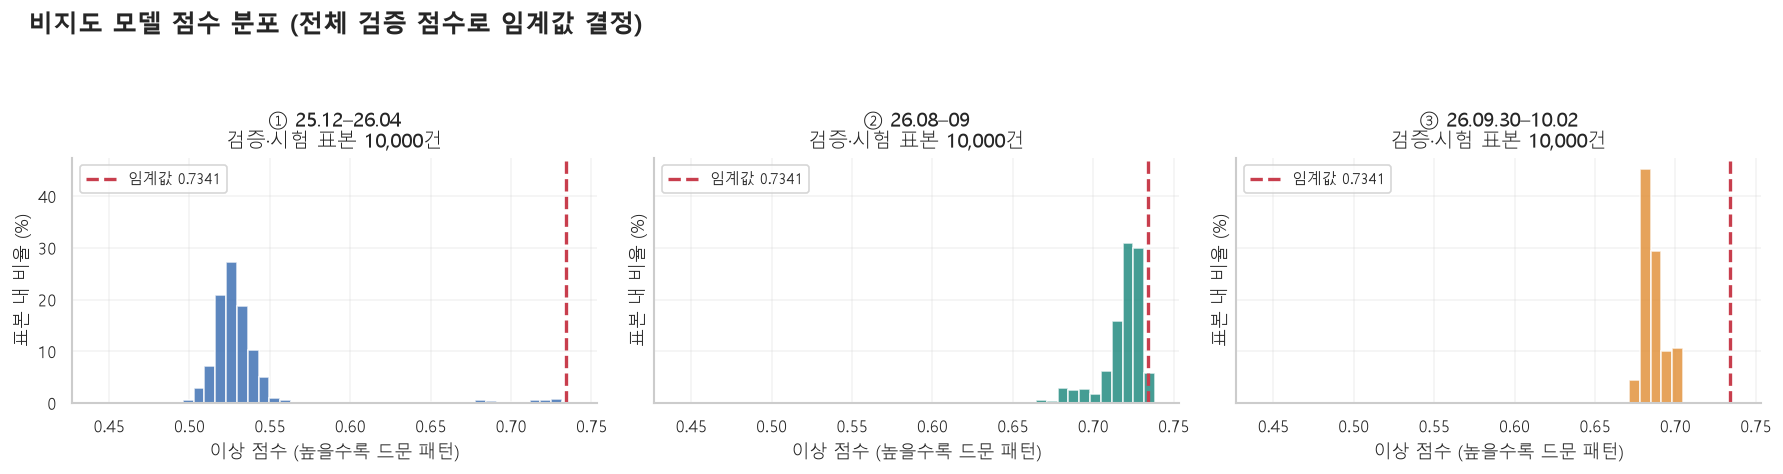

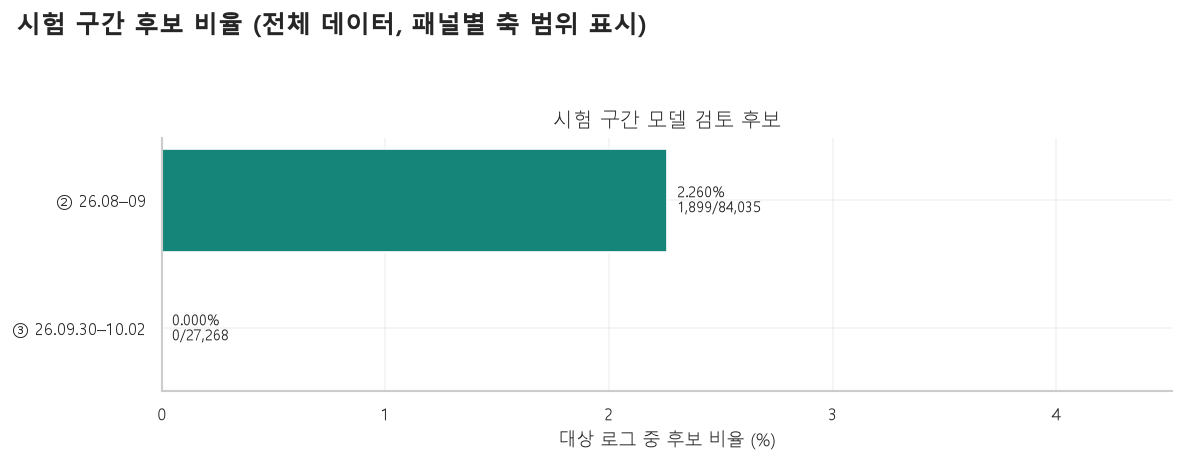

**실제 결과**

- ② 26.08–09 / 시험 구간 모델 검토 후보: 1,899 / 84,035건 (2.260%).
- ③ 26.09.30–10.02 / 시험 구간 모델 검토 후보: 0 / 27,268건 (0.000%).

**의미**: 분모는 각 규칙의 비교 가능한 로그입니다(별도 조건이 없는 규칙은 기간 전체 행). 서로 다른 규칙의 후보는 중복될 수 있어 합산하면 안 됩니다. 후보 0건과 비교 불가는 다릅니다.

**모델 개발에 반영**: 낮은 비율도 실제 건수로 확인해 검토 대상을 정합니다. 정합성 규칙은 비지도 모델 점수와 별도로 표시하며 확정 장애 라벨로 사용하지 않습니다.

**실제 결과**

- 시험 전체 111,303건 중 후보 1,899건 (1.71%). 임계값 0.7341; 검증 점수의 99% 분위수입니다.

**의미**: 히스토그램은 표본이지만 시험 후보율은 전체 시험 로그로 계산했습니다. 99% 검증 분위수를 적용해도 기간 변화와 점수 동률 때문에 시험 후보율이 1%일 필요는 없습니다.

**모델 개발에 반영**: 이 비율은 정확도가 아니라 사람이 검토할 양입니다. 상태·업무·수집 변화와 후보를 교차 검토하고 실제 장애 확인 표본으로 precision/recall을 평가합니다.

In [25]:
plot_model_scores(df, model_result, model_profile)


### 10.2 후보의 상태·정합성은 사후 해석입니다

후보/비후보 각각을 100%로 맞춘 교차표입니다. `status=F`를 정답으로 둔
학습·평가가 아니므로 실패 상태가 많은 것을 precision으로 해석하지 않습니다.

In [26]:
test_view = df.loc[model_result["split"].eq("test"), ["status", 'integrity_candidate']].join(model_result[["anomaly_candidate"]])
display(pd.crosstab(test_view["anomaly_candidate"], text(test_view["status"]), normalize="index").mul(100).round(2))
display(pd.crosstab(test_view["anomaly_candidate"], test_view['integrity_candidate'], normalize="index").mul(100).round(2))
note("위 표의 각 행은 후보 또는 비후보 집단 내부의 상태/정합성 비율입니다. 두 집단의 건수는 서로 다릅니다.",
     "후보는 희귀한 행동 패턴입니다. 실패 상태·정합성 후보와 겹칠 수 있지만 같지 않으며, 성공 상태의 후보도 검토 대상입니다.",
     "상위 점수와 상태·업무·지연 근거를 함께 검토해 실제 이상 라벨을 확보합니다.")
del test_view


status,F,H,S,Z
anomaly_candidate,,,,
False,66.35,0.0,33.61,0.04
True,100.00,0.0,0.00,0.00


integrity_candidate,False,True
anomaly_candidate,,
False,100.0,0.0
True,100.0,0.0


**실제 결과**

- 위 표의 각 행은 후보 또는 비후보 집단 내부의 상태/정합성 비율입니다. 두 집단의 건수는 서로 다릅니다.

**의미**: 후보는 희귀한 행동 패턴입니다. 실패 상태·정합성 후보와 겹칠 수 있지만 같지 않으며, 성공 상태의 후보도 검토 대상입니다.

**모델 개발에 반영**: 상위 점수와 상태·업무·지연 근거를 함께 검토해 실제 이상 라벨을 확보합니다.

### 10.3 PCA로 보는 피처 공간

PCA는 학습 데이터에만 맞추고 기간별 균형 표본을 투영합니다.
그림은 구조를 살펴보는 2차원 요약이며 분리되어 보인다는 사실만으로 이상을 확정하지 않습니다.

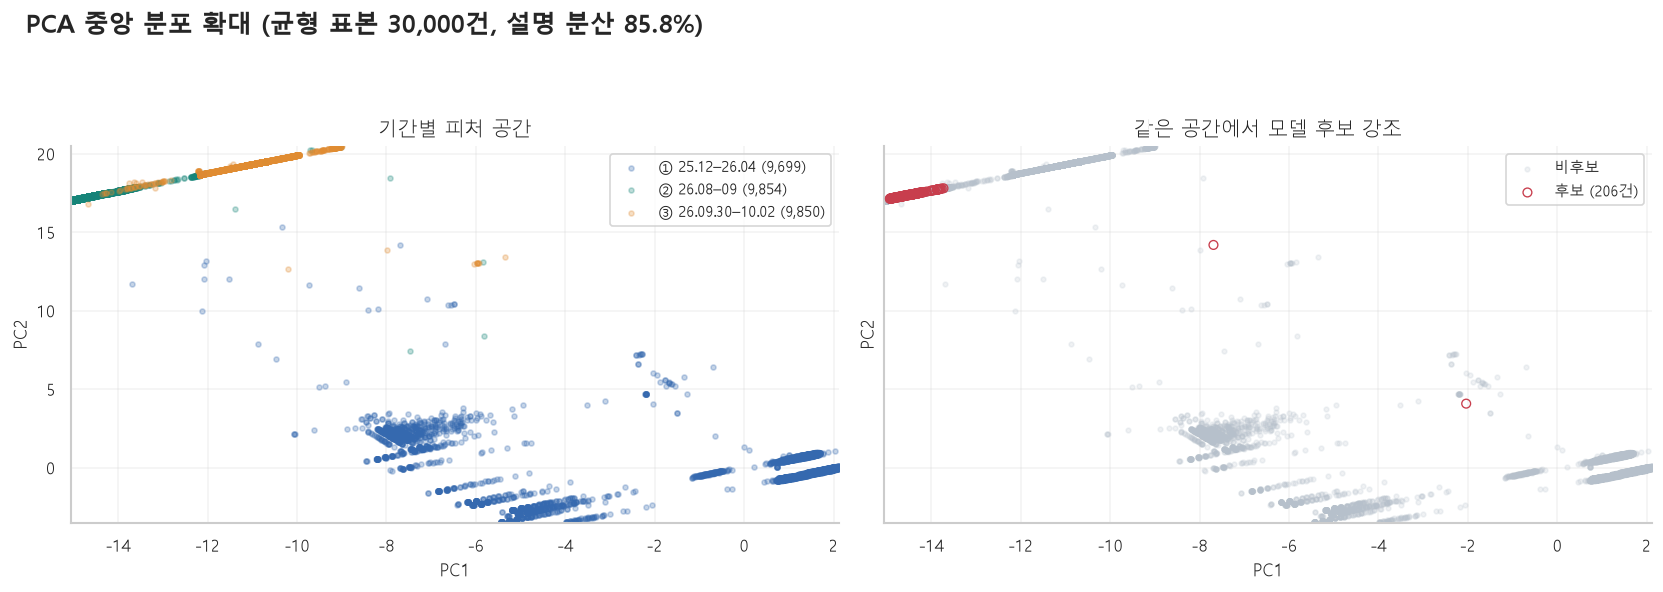

**실제 결과**

- 각 축의 표본 0.5–99.5% 범위를 확대했습니다. 화면 밖 597건 중 후보 0건은 모델 계산에서 제외하지 않았습니다. 전체 투영 표본 후보 206건.

**의미**: 왼쪽은 기간 차이, 오른쪽은 후보의 위치를 보여줍니다. PCA 2축은 전체 피처 정보의 일부만 보존하므로 떨어진 군집이나 점 하나를 실제 이상으로 확정할 수 없습니다.

**모델 개발에 반영**: 분리된 기간은 도메인 변화의 단서로 보고 원래 피처와 업무 종류를 확인합니다. 화면 밖 후보도 상위 점수 표로 함께 검토합니다.

0          log_duration_ms
1      missing_duration_ms
2         log_processCount
3     missing_processCount
4       missing_retryCount
5                 hour_sin
6                 hour_cos
7              weekday_sin
8              weekday_cos
9       rarity_interfaceId
10      unseen_interfaceId
11        rarity_route_key
12        unseen_route_key
13    rarity_interfaceType
14    unseen_interfaceType
Name: model_input_feature, dtype: str

In [27]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(fitted["X_train"])
pca_sample = sample_by_period(df.loc[model_result["anomaly_score"].notna()], PLOT_SAMPLE, RANDOM_STATE)
coords = pca.transform(fitted["transform"](pca_sample))
projection = pd.DataFrame(coords, columns=["PC1", "PC2"], index=pca_sample.index)
projection["source_period"] = pca_sample["source_period"]
projection["candidate"] = model_result.loc[pca_sample.index, "anomaly_candidate"]
plot_projection(projection, pca.explained_variance_ratio_.sum())
display(pd.Series(model_profile["features"], name="model_input_feature"))


## 11. 모델 개발로 이어지는 해석

- 통합 분포와 기간별 변화가 크면 업무 그룹 기준선과 운영 환경별 모델을 비교합니다.
- 처리시간의 긴 꼬리에는 로그 변환을, 시간 주기에는 sin/cos 표현을 사용합니다.
- 거래 ID는 결합 키이며 모델 입력에서 제외합니다. 업무 ID는 범주 빈도나 별도 표현을 검토합니다.
- 결측·재시도·수집 범위가 만든 후보와 실제 실행 이상 후보를 사람 검토로 구분합니다.
- 실제 성능 평가는 검토로 확정된 표본이나 통제된 장애 주입 데이터가 필요합니다.
- 이후 비교 모델은 LOF/강건 공분산/Autoencoder 및 시계열 예측 잔차 모델로 확장할 수 있습니다.
  모든 대치·변환·기준선·임계값은 학습/검증 단계에서만 결정합니다.